# Assignment 1: Building a Shallow Neural Network

**Course:** AAI 6640 — Applied Deep Learning  
**Module:** Week 3 (3.10)  
**Author:** Muhammad Obaidullah Abdul Salam  
**Dataset:** California Housing (scikit-learn)  
**Task:** Regression — predict median house value (units of $100,000)  

## Overview

**Objective:** predict the median house value of a California census block group from eight numeric features with a shallow neural network (one hidden `Dense` layer), and compare how hidden-layer size and activation function affect learning.

**Approach:** load → explore → split → standardize → train → compare → select → evaluate once on test.

**Conventions:** the target and MAE are in units of \$100,000 (2.5 ≈ \$250,000); MSE is in (\$100,000)². One fixed seed (`SEED = 42`) governs the data split and every training run.

**Results at a glance.** Every choice used validation results only; the test set was scored once, in Step 6. Losses are MSE in (\$100,000)².

| Configuration | Parameters | Final training loss | Best validation loss | Epoch of best val loss |
|---|---|---|---|---|
| 16 units · ReLU | 161 | 0.3109 | 0.3312 | 97 |
| 64 units · ReLU (baseline) | 641 | 0.2854 | 0.3126 | 99 |
| **256 units · ReLU (final)** | 2,561 | 0.2526 | **0.2835** | 100 |
| 256 units · Tanh | 2,561 | 0.3030 | 0.3226 | 100 |
| 256 units · Sigmoid | 2,561 | 0.3171 | 0.3351 | 100 |

| Final model: 256 units · ReLU, best-epoch (100) weights | Value |
|---|---|
| Test MSE | 0.2668 |
| Test MAE | 0.3530 (≈ \$35,300 average absolute error) |

## Setup

All imports, constants, and display settings.

**Reproducibility.**

- **Dependencies.** Python, TensorFlow, Keras (TensorFlow backend), scikit-learn, NumPy, pandas, and Matplotlib, at the versions the cell below prints. CPU only; no GPU is used.
- **Seed and determinism.** `SEED = 42` fixes the data split (Step 2), and `keras.utils.set_random_seed(SEED)` resets the Python, NumPy, and TensorFlow generators immediately before each model is built (Step 3), so every configuration starts from the same random state. `tf.config.experimental.enable_op_determinism()` makes TensorFlow's operations deterministic, so a rerun with the same versions on the same hardware reproduces every training history exactly.
- **Data.** `fetch_california_housing()` downloads the dataset on the first run, so that run needs an internet connection, and caches it in `~/scikit_learn_data`; later runs read the cache. The only preprocessing is Step 2's split and standardization.
- **Runtime.** A full top-to-bottom run in a fresh kernel took about 2 minutes (126 s and 129 s in two runs) on an Apple M1 Pro CPU. Nearly all of it is the five training runs of Steps 3–5, about 22 to 24 s each.

In [1]:
import os
import platform

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # before TensorFlow loads; hides C++ notices

from collections.abc import Callable, Sequence
from dataclasses import dataclass, replace
from functools import cache

import keras
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from matplotlib_inline.backend_inline import set_matplotlib_formats
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
EPOCHS = 100
BATCH_SIZE = 32
VAL_FRACTION = 0.15
TEST_FRACTION = 0.15
HIDDEN_SIZES = (16, 64, 256)
ACTIVATIONS = ("relu", "tanh", "sigmoid")
CONVERGENCE_TOLERANCE = 0.05  # "converged": validation loss within 5% of its best
STABILITY_WINDOW = 20  # final epochs over which jitter and drift are measured
CHECKPOINTS = [1, 2, 5, 10, 25, 50, 75, EPOCHS]  # epochs tabulated beside the curves
TARGET_UNIT_DOLLARS = 100_000  # the target and MAE are in units of $100,000
# Comparison colour per configuration (ReLU by width); C0/C1 are train/val, C3 the cap.
CONFIG_COLORS = {16: "C2", 64: "C9", 256: "C4", "tanh": "C5", "sigmoid": "C8"}

tf.config.experimental.enable_op_determinism()

set_matplotlib_formats("retina")
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "font.size": 11,
        "axes.titleweight": "bold",
        "figure.titlesize": "x-large",
        "figure.titleweight": "bold",
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.3,
        "legend.frameon": False,
    }
)
pd.set_option("display.precision", 4)
pd.set_option("display.html.use_mathjax", False)  # "$" in tables is money, not TeX

print(
    f"Python {platform.python_version()} | TensorFlow {tf.__version__} | "
    f"Keras {keras.__version__} | scikit-learn {sklearn.__version__} | "
    f"NumPy {np.__version__} | pandas {pd.__version__} | "
    f"Matplotlib {matplotlib.__version__}"
)

Python 3.12.11 | TensorFlow 2.21.0 | Keras 3.15.1 | scikit-learn 1.9.1 | NumPy 2.5.3 | pandas 3.0.6 | Matplotlib 3.11.2


## Step 1 — Data loading and exploration

The data come from the 1990 U.S. Census, one row per census block group: the smallest area for which the Census Bureau publishes sample data, typically 600 to 3,000 people. Meanings follow the dataset's own description (`housing.DESCR`).

| Feature | Meaning | Unit |
|---|---|---|
| `MedInc` | Median income in the block group | \$10,000 |
| `HouseAge` | Median house age in the block group | years |
| `AveRooms` | Average number of rooms per household | rooms per household |
| `AveBedrms` | Average number of bedrooms per household | bedrooms per household |
| `Population` | Block group population | people |
| `AveOccup` | Average number of household members | people per household |
| `Latitude` | Block group latitude | degrees north |
| `Longitude` | Block group longitude | degrees east (negative = west) |
| `MedHouseVal` (target) | Median house value for the block group | \$100,000 |

DESCR gives no unit for `MedInc`; it is conventionally read in tens of thousands of dollars.

In [2]:
housing = fetch_california_housing(as_frame=True)
X, y = housing.data, housing.target
TARGET_CAP = float(y.max())  # plain float, so == also matches the cap in float32 arrays

print(f"Feature matrix X: {X.shape}")
print(f"Target array y:   {y.shape} ({y.name})")
print(f"Features: {', '.join(X.columns)}")

Feature matrix X: (20640, 8)
Target array y:   (20640,) (MedHouseVal)
Features: MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude


### Summary statistics

`describe` with the 1st and 99th percentiles added to expose the tails, plus skewness.

In [3]:
(
    X.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])
    .T.drop(columns="count")
    .assign(skewness=X.skew())
)

,mean,std,min,1%,25%,50%,75%,99%,max,skewness
MedInc,3.8707,1.8998,0.4999,1.0696,2.5634,3.5348,4.7432,10.5965,15.0001,1.6467
HouseAge,28.6395,12.5856,1.0000,4.0000,18.0000,29.0000,37.0000,52.0000,52.0000,0.0603
AveRooms,5.4290,2.4742,0.8462,2.5811,4.4407,5.2291,6.0524,10.3570,141.9091,20.6979
AveBedrms,1.0967,0.4739,0.3333,0.8728,1.0061,1.0488,1.0995,2.1275,34.0667,31.3170
Population,1425.4767,1132.4621,3.0000,88.0000,787.0000,1166.0000,1725.0000,5805.8300,35682.0000,4.9359
AveOccup,3.0707,10.3860,0.6923,1.5367,2.4297,2.8181,3.2823,5.3948,1243.3333,97.6396
Latitude,35.6319,2.1360,32.5400,32.6800,33.9300,34.2600,37.7100,40.6261,41.9500,0.4660
Longitude,-119.5697,2.0035,-124.3500,-123.2200,-121.8000,-118.4900,-118.0100,-116.2900,-114.3100,-0.2978


### Target distribution

Bins are \$10,000 wide; the values stored at the cap get their own bar.

MedHouseVal ($100,000): mean 2.0686, median 1.7970; 965 of 20,640 block groups (4.68%) at the cap 5.00001


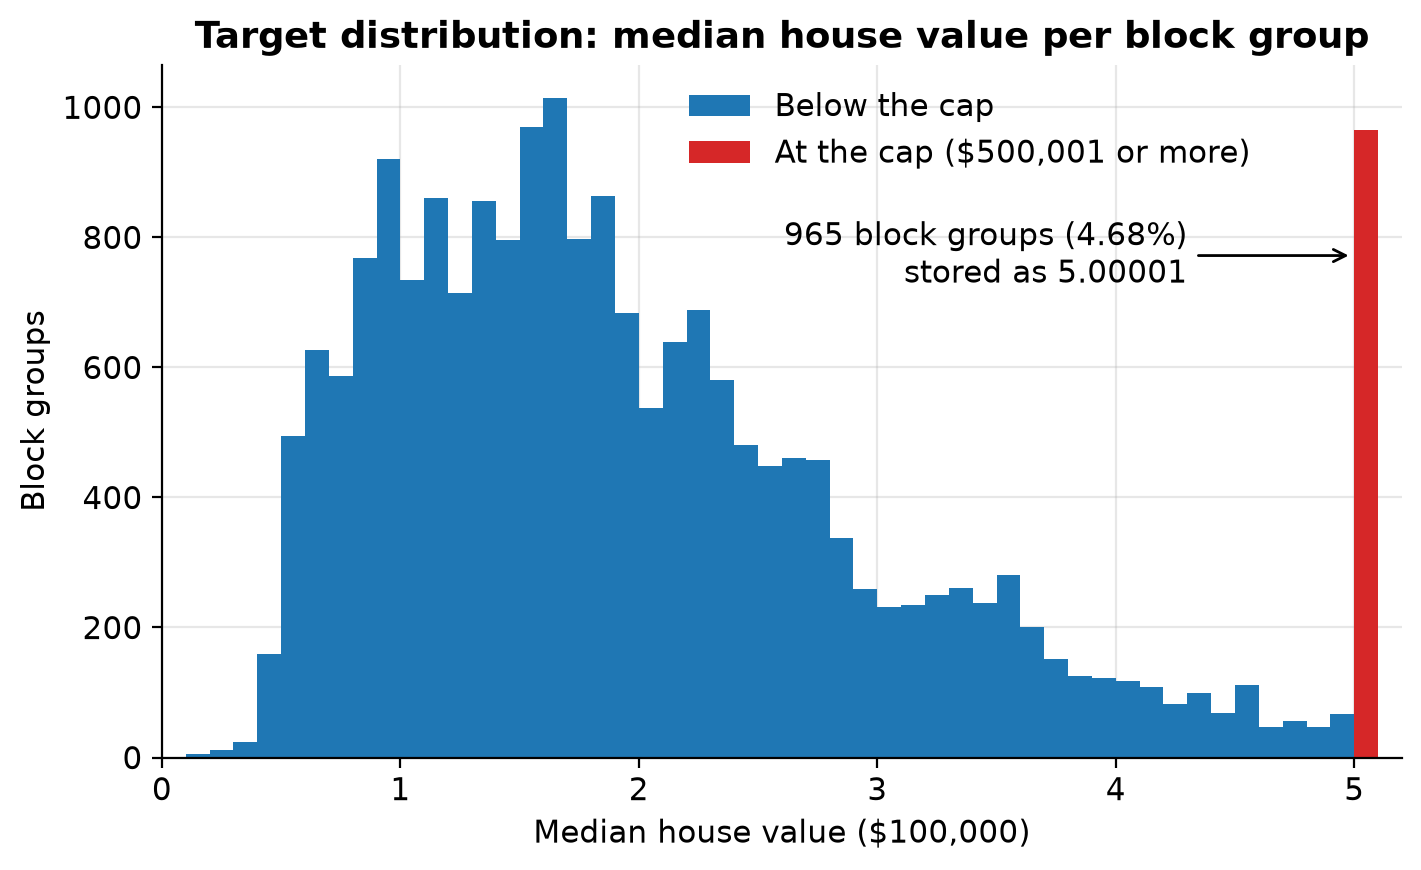

In [4]:
at_cap = y == TARGET_CAP
n_capped, share_capped = int(at_cap.sum()), at_cap.mean()
print(
    f"{y.name} ($100,000): mean {y.mean():.4f}, median {y.median():.4f}; "
    f"{n_capped:,} of {len(y):,} block groups ({share_capped:.2%}) "
    f"at the cap {TARGET_CAP}"
)

_, ax = plt.subplots()
ax.hist(y[~at_cap], bins=np.linspace(0, 5, 51), label="Below the cap")
ax.bar(
    TARGET_CAP,
    n_capped,
    width=0.1,
    align="edge",
    color="C3",
    label=r"At the cap (\$500,001 or more)",
)
ax.annotate(
    f"{n_capped} block groups ({share_capped:.2%})\nstored as {TARGET_CAP}",
    xy=(TARGET_CAP, 0.8 * n_capped),
    xytext=(4.3, 0.8 * n_capped),
    ha="right",
    va="center",
    arrowprops={"arrowstyle": "->"},
)
ax.set(
    title="Target distribution: median house value per block group",
    xlabel=r"Median house value (\$100,000)",
    ylabel="Block groups",
    xlim=(0, 5.2),
)
ax.legend(loc="upper right", bbox_to_anchor=(0.9, 1))
plt.show()

### Feature scales

In [5]:
feature_std = X.std().sort_values(ascending=False)
pd.DataFrame(
    {
        "Standard deviation": feature_std,
        "Ratio to smallest": (feature_std / feature_std.iloc[-1]).round(1),
    }
)

,Standard deviation,Ratio to smallest
Population,1132.4621,2389.6
HouseAge,12.5856,26.6
AveOccup,10.3860,21.9
AveRooms,2.4742,5.2
Latitude,2.1360,4.5
Longitude,2.0035,4.2
MedInc,1.8998,4.0
AveBedrms,0.4739,1.0


### Missing and invalid values

Top codes are the census caps, taken from each column's maximum; heavy tails compare each maximum with the 99th percentile.

In [6]:
def quality_checks(frame: pd.DataFrame) -> pd.DataFrame:
    """Missing, non-finite, duplicate, and impossible values; top codes; heavy tails."""

    def rows(mask: pd.Series) -> str:
        """How many rows satisfy `mask`, with their share of all rows."""
        return f"{mask.sum():,} rows ({mask.mean():.2%})"

    checks = [
        ("Missing values", f"{frame.isna().to_numpy().sum()}"),
        ("Non-finite values", f"{(~np.isfinite(frame.to_numpy())).sum()}"),
        ("Duplicate rows", f"{frame.duplicated().sum()}"),
        ("AveBedrms > AveRooms", rows(frame["AveBedrms"] > frame["AveRooms"])),
        ("AveOccup < 1 (fewer residents than households)", rows(frame["AveOccup"] < 1)),
    ]
    for column in ("MedHouseVal", "HouseAge", "MedInc"):
        top = frame[column].max()
        checks.append((f"{column} = {top:g} (top code)", rows(frame[column] == top)))
    for column in ("AveRooms", "AveBedrms", "Population", "AveOccup"):
        top, p99 = frame[column].max(), frame[column].quantile(0.99)
        result = f"{top:,.2f} vs {p99:,.2f} ({top / p99:.1f}×)"
        checks.append((f"{column}: max vs 99th percentile", result))
    return pd.DataFrame(checks, columns=["Check", "Result"]).set_index("Check")


quality_checks(housing.frame)

,Result
Check,
Missing values,0
Non-finite values,0
Duplicate rows,0
AveBedrms > AveRooms,0 rows (0.00%)
AveOccup < 1 (fewer residents than households),3 rows (0.01%)
MedHouseVal = 5.00001 (top code),965 rows (4.68%)
HouseAge = 52 (top code),"1,273 rows (6.17%)"
MedInc = 15.0001 (top code),49 rows (0.24%)
AveRooms: max vs 99th percentile,141.91 vs 10.36 (13.7×)


### Observations

- **Scales.** Standard deviations run from 0.4739 (`AveBedrms`) to 1,132.4621 (`Population`), a ratio of 2,389.6: more than three orders of magnitude. `Population` dwarfs every other feature, and `HouseAge` (12.5856) and `AveOccup` (10.3860) in turn sit well above the remaining five (0.4739 to 2.4742).
- **Data quality.** No missing values, no non-finite values, no duplicate rows, and no block group with more bedrooms than rooms. One check fails: 3 block groups (0.01%) have `AveOccup` below 1 (the minimum is 0.6923), meaning fewer residents than households, which no real average household size allows.
- **Target.** Right-skewed, with the mean (2.0686) above the median (1.7970) and a long upper tail that runs into the cap.
- **Censoring.** Three columns are top-coded, and above each code the true values are unknown. The target stores 965 block groups (4.68%) as 5.00001, the census code for \$500,001 or more: the isolated spike at the right of the histogram, nearly as tall as its highest bin. `HouseAge` stops at 52 for 1,273 rows (6.17%; its 99th percentile already equals the maximum), and `MedInc` at 15.0001 for 49 rows (0.24%).
- **Heavy tails.** `AveOccup` reaches 1,243.33 against a 99th percentile of 5.39 (230.5×, skewness 97.6396); `AveBedrms`, `AveRooms`, and `Population` reach 16.0×, 13.7×, and 6.1× their 99th percentiles. DESCR explains the room and bedroom extremes: block groups with few households and many empty houses, such as vacation resorts.
- **Limitations.** Prices are from 1990, so every dollar figure in this notebook is in 1990 dollars. Each row aggregates a block group's households, so the model predicts a neighborhood median, not the price of a house. Neighboring block groups share location, income, and housing stock, and a random split puts such neighbors on both sides: validation and test scores measure interpolation between known areas and likely overstate accuracy on unseen regions.

### Implications for preprocessing

- **Standardize the features with training statistics only.** Feature scales differ by a factor of 2,389.6, so every feature is rescaled to mean 0 and standard deviation 1, using the training split's statistics alone (Step 2) so that no validation or test information reaches training.
- **No imputation.** Nothing is missing or non-finite.
- **The target stays in its original units.** `MedHouseVal` is not scaled, so MAE reads directly in \$100,000 and MSE in (\$100,000)².
- **Outliers are kept, as are the 3 inconsistent rows.** The spec's preprocessing is the split and standardization alone, and keeping every published row lets validation and test measure error on the data as released. Standardization does not bound the outliers: a linear rescaling preserves each value's relative position, so the `AveOccup` maximum stays as far beyond the bulk of the data as before.
- **The cap cannot be fixed by preprocessing.** No transform recovers values above \$500,001: the 965 capped targets are lower bounds, not measurements. The model trains against these floors, has no training target above the cap, and has its errors on capped block groups measured against a censored label; Step 6 reads the test errors with this in mind.

## Step 2 — Data preprocessing

Split first (70 / 15 / 15, `random_state=SEED`), then fit the scaler on the training features alone and apply it, unchanged, to validation and test.

In [7]:
@dataclass(frozen=True)
class Split:
    """One partition: features `X` (rows × 8) and target `y` (rows,), both float32."""

    X: np.ndarray
    y: np.ndarray


@dataclass(frozen=True)
class Splits:
    """The training, validation, and test partitions."""

    train: Split
    val: Split
    test: Split


def split_data(X: pd.DataFrame, y: pd.Series) -> Splits:
    """Split rows 70 / 15 / 15 into training, validation, and test with a fixed seed."""
    features, target = X.to_numpy(dtype=np.float32), y.to_numpy(dtype=np.float32)
    holdout = VAL_FRACTION + TEST_FRACTION
    X_train, X_hold, y_train, y_hold = train_test_split(
        features, target, test_size=holdout, random_state=SEED
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_hold, y_hold, test_size=TEST_FRACTION / holdout, random_state=SEED
    )
    return Splits(Split(X_train, y_train), Split(X_val, y_val), Split(X_test, y_test))


def standardize(splits: Splits) -> tuple[Splits, StandardScaler]:
    """Fit a scaler on the training features only and apply it to every split."""
    scaler = StandardScaler().fit(splits.train.X)
    train, val, test = (
        replace(part, X=scaler.transform(part.X))
        for part in (splits.train, splits.val, splits.test)
    )
    return Splits(train, val, test), scaler


raw = split_data(X, y)
data, scaler = standardize(raw)

In [8]:
def split_profile(part: Split, n_total: int) -> dict[str, float | str]:
    """Size, target, and scaled-feature statistics of one split; shares in percent."""
    std = part.X.std(axis=0)
    return {
        "Rows": len(part.y),
        "Share of total (%)": f"{100 * len(part.y) / n_total:.2f}",
        "Target mean": part.y.mean(),
        "At cap (%)": f"{100 * np.mean(part.y == TARGET_CAP):.2f}",
        "Max |feature mean|": np.abs(part.X.mean(axis=0)).max(),
        "Mean feature std": std.mean(),
        "Min feature std": std.min(),
        "Max feature std": std.max(),
    }


def fitted_on(scaler: StandardScaler, features: np.ndarray) -> bool:
    """Whether the scaler holds the column means and population stds of `features`."""
    return np.allclose(scaler.mean_, features.mean(axis=0)) and np.allclose(
        scaler.scale_, features.std(axis=0)
    )


print(
    "scaler.mean_ / scale_ equal the raw training split's mean / population std:",
    fitted_on(scaler, raw.train.X),
)
print(
    "scaler.mean_ / scale_ equal the full dataset's mean / population std:",
    fitted_on(scaler, X.to_numpy()),
)
parts = {"Training": data.train, "Validation": data.val, "Test": data.test}
profiles = {name: split_profile(part, len(X)) for name, part in parts.items()}
pd.DataFrame.from_dict(profiles, orient="index").round(4)

scaler.mean_ / scale_ equal the raw training split's mean / population std: True
scaler.mean_ / scale_ equal the full dataset's mean / population std: False


,Rows,Share of total (%),Target mean,At cap (%),Max |feature mean|,Mean feature std,Min feature std,Max feature std
Training,14448,70.00,2.0692,4.78,0.0000,1.0000,1.0000,1.0000
Validation,3096,15.00,2.0680,4.49,0.0564,0.8097,0.0666,1.0433
Test,3096,15.00,2.0660,4.39,0.0175,0.9819,0.1603,1.5388


**Reading the check.** The split yields 14,448 / 3,096 / 3,096 rows (70.00 / 15.00 / 15.00%). The scaler's statistics equal the raw training split's mean and population standard deviation and differ from the full dataset's, so it saw training rows only. On the training split every feature has mean 0 and standard deviation 1 to four decimals (min and max feature std both 1.0000). Validation and test were scaled with the training statistics, not their own, so their feature means stay close to 0 (largest absolute 0.0564 and 0.0175) but their feature standard deviations spread in both directions: from 0.0666 to 1.0433 on validation and from 0.1603 to 1.5388 on test. Test's mean feature std (0.9819) looks like unit scale only because spreads above and below 1 cancel; validation's is 0.8097. This follows from the heavy tails of Step 1: a few extreme rows set the heavy-tailed features' standard deviations, so a holdout split's scaled spread depends on how many of those rows it holds, falling below 1 when it holds proportionally fewer than the training split and rising above 1 when it holds more. Target means (2.0692, 2.0680, 2.0660) and capped shares (4.78%, 4.49%, 4.39%) are similar across splits, consistent with a representative split.

**Why feature scaling matters.** Training updates every weight from the gradient of the MSE. On raw inputs, `Population` (standard deviation 1,132.4621) would dominate each hidden unit's pre-activation while `AveBedrms` (0.4739) barely registered, and the loss surface would be steep along some weights and flat along others, which slows and destabilizes gradient-based training. Tanh and sigmoid saturate: their slopes vanish once the pre-activation moves more than a few units from zero, and raw inputs in the thousands would push those units there from the first step, stalling learning. Keras's default Glorot-uniform initialization sizes the initial weights for inputs of roughly unit scale; standardized inputs meet that assumption.

**Why fitting the scaler on the full dataset is data leakage.** The scaler's means and standard deviations are learned parameters, part of the model. Fitting them on all 20,640 rows would let validation and test statistics shape the transform the network trains on, so those rows would no longer be held out: validation scores would be optimistically biased, and both model selection and the final test estimate would be invalid. Fitting on the 14,448 training rows alone matches deployment, where new data are transformed with statistics fixed in advance.

## Step 3 — Baseline model

The spec's reference configuration, from which Steps 4 and 5 vary one factor at a time.

| Layer | Specification |
|---|---|
| Input | 8 features, standardized with the training statistics (Step 2) |
| Hidden | 1 `Dense` layer, 64 units, ReLU |
| Output | 1 unit, linear activation |

| Training setting | Value |
|---|---|
| Data | Weights are fit on the 14,448 training rows; the 3,096 validation rows are scored after every epoch and never used for fitting; the target stays unscaled. Test rows play no part until Step 6. |
| Optimizer | Adam with the Keras defaults (learning rate 0.001, β₁ = 0.9, β₂ = 0.999, ε = 10⁻⁷), fixed |
| Loss | MSE, in (\$100,000)² |
| Metric | MAE, in \$100,000 |
| Epochs | 100 (`EPOCHS`), all trained and recorded; no early stopping |
| Batch size | 32 (`BATCH_SIZE`), the Keras default: 452 parameter updates per epoch on the 14,448 training rows; each 100-epoch run takes about 22 to 24 s on CPU (Setup) |
| Shuffling | Training rows reshuffled every epoch (Keras default) |
| Initialization | Keras defaults: Glorot-uniform kernels, zero biases |
| Seed | `SEED = 42`, reset with `keras.utils.set_random_seed(SEED)` immediately before each model is built; with `enable_op_determinism()` (Setup), every run is reproducible |
| Weights kept | Those of the epoch with the lowest validation loss, restored after epoch 100 |

**Controlled comparison.** Every later model reuses this pipeline unchanged (the split, the scaling, every setting above, and the seed) except for the one factor under study:

| Step | Changes | Held at | What it tests |
|---|---|---|---|
| 3 | Nothing: the reference | 64 units, ReLU | How the reference learns: convergence, under- or overfitting |
| 4 | Hidden units: 16, 64, 256 | ReLU | Capacity: how width changes the fit and the validation loss |
| 5 | Activation: ReLU, Tanh, Sigmoid | The hidden size Step 4 selects | How the activation changes convergence speed, stability, and validation loss |

### Training pipeline

`train` resets the seed, builds the model, and fits it for 100 epochs; `Run` holds the model, its per-epoch history, and the numbers derived from them. Two additions go beyond the spec's minimum, and neither changes how a model trains:

- **In-memory best weights.** `RestoreBestWeights` copies the weights at each new validation low and loads the best copy after the last epoch, so Step 6 evaluates exactly the weights validation selected, without retraining, while the curves still cover all 100 epochs.
- **Run cache.** `run` trains each distinct `Config` once and returns the cached `Run` afterwards; a seeded, deterministic rerun of an identical `Config` gives identical results, so reusing a run (the baseline in Step 4, Step 4's ReLU run at the chosen size in Step 5) does not change the comparison.

In [9]:
@dataclass(frozen=True)
class Config:
    """One network configuration: hidden-layer width and Keras activation name."""

    hidden_units: int
    activation: str

    @property
    def activation_name(self) -> str:
        """Display name of the activation, e.g. "ReLU"."""
        return {"relu": "ReLU", "tanh": "Tanh", "sigmoid": "Sigmoid"}[self.activation]

    @property
    def label(self) -> str:
        """Display name, e.g. "64 units · ReLU"."""
        return f"{self.hidden_units} units · {self.activation_name}"

    @property
    def color(self) -> str:
        """Comparison-plot colour: ReLU runs by width, the others by activation."""
        relu = self.activation == "relu"
        return CONFIG_COLORS[self.hidden_units if relu else self.activation]


def build_model(config: Config, n_features: int) -> keras.Model:
    """Input → Dense(hidden_units, activation) → Dense(1), compiled per the spec."""
    model = keras.Sequential(
        [
            keras.Input(shape=(n_features,)),
            keras.layers.Dense(
                config.hidden_units, activation=config.activation, name="hidden"
            ),
            keras.layers.Dense(1, name="output"),
        ],
        name=f"{config.hidden_units}_units_{config.activation}",
    )
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model


class RestoreBestWeights(keras.callbacks.Callback):
    """Keep the weights of the lowest-validation-loss epoch; restore them at the end."""

    def __init__(self) -> None:
        super().__init__()
        self.best_loss = np.inf
        self.best_weights: list[np.ndarray] = []

    def on_epoch_end(self, epoch: int, logs: dict[str, float]) -> None:
        # Strict < keeps the earliest epoch on ties, as Run.best_epoch (idxmin) does.
        if logs["val_loss"] < self.best_loss:
            self.best_loss = logs["val_loss"]
            self.best_weights = self.model.get_weights()

    def on_train_end(self, logs: dict[str, float] | None = None) -> None:
        self.model.set_weights(self.best_weights)


@dataclass(frozen=True)
class Run:
    """One trained configuration: best-validation weights and the per-epoch history."""

    config: Config
    model: keras.Model
    history: pd.DataFrame

    @property
    def best_epoch(self) -> int:
        """Epoch of the lowest validation loss; the model keeps its weights."""
        return int(self.history["val_loss"].idxmin())

    @property
    def best_val_loss(self) -> float:
        """Lowest validation MSE over all epochs."""
        return float(self.history["val_loss"].min())

    @property
    def final_train_loss(self) -> float:
        """Training MSE of the last epoch."""
        return float(self.history["loss"].iloc[-1])


def train(config: Config, data: Splits) -> Run:
    """Seed, build, and fit one configuration; history is indexed by 1-based epoch."""
    keras.utils.set_random_seed(SEED)
    model = build_model(config, n_features=data.train.X.shape[1])
    history = model.fit(
        data.train.X,
        data.train.y,
        validation_data=(data.val.X, data.val.y),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[RestoreBestWeights()],
        verbose=0,
    ).history
    epochs = pd.RangeIndex(1, EPOCHS + 1, name="epoch")
    return Run(config, model, pd.DataFrame(history, index=epochs))


@cache
def run(config: Config) -> Run:
    """Train `config` on the global `data` once; afterwards return the cached run."""
    return train(config, data)

### Baseline run

In [10]:
baseline = run(Config(64, "relu"))
baseline.model.summary()
print(
    f"{baseline.config.label}: final training loss {baseline.final_train_loss:.4f}, "
    f"best validation loss {baseline.best_val_loss:.4f} at epoch "
    f"{baseline.best_epoch} of {EPOCHS} (MSE, ($100,000)²)"
)

Model: "64_units_relu"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden (Dense)                  │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,925 (7.52 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,284 (5.02 KB)

64 units · ReLU: final training loss 0.2854, best validation loss 0.3126 at epoch 99 of 100 (MSE, ($100,000)²)


The hidden layer holds 8 × 64 weights and 64 biases (576 parameters), the output layer 64 weights and 1 bias (65): 641 trainable parameters for 14,448 training rows. `Optimizer params` (1,284) is optimizer state, not part of the network, and `Total params` (1,925) adds it to the 641.

### Loss curves

Training and validation MSE on the same axes; the dotted line drops from the best validation epoch, whose weights the model keeps. The y-axis of every per-run loss plot runs from the lowest training loss to the highest validation loss, so epoch 1's training loss (listed in the table below) runs off the top: Keras reports training loss as the mean over the epoch's batches, the first of which meet untrained weights, while validation is scored after the epoch's last update.

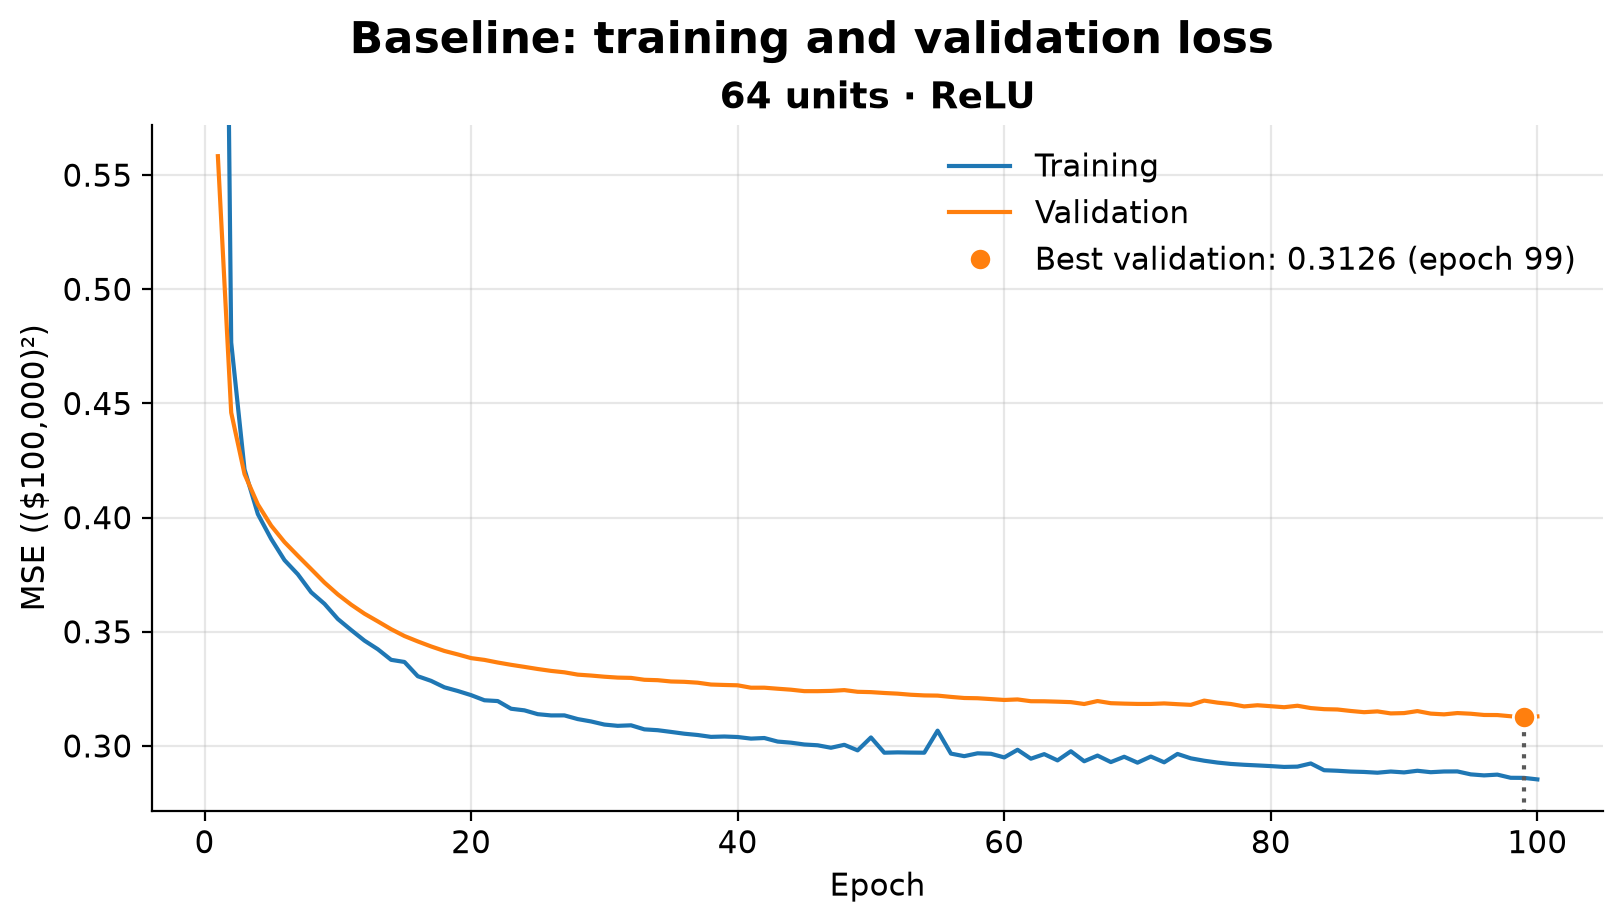

In [11]:
def plot_curves(runs: Sequence[Run], title: str) -> None:
    """Training and validation MSE per epoch, one panel per run, best epoch marked."""
    fig, axes = plt.subplots(
        1,
        len(runs),
        figsize=(max(8.0, 4.3 * len(runs)), 4.5),
        sharey=True,
        squeeze=False,
        layout="constrained",
    )
    for ax, trained in zip(axes[0], runs, strict=True):
        curves, epoch, loss = trained.history, trained.best_epoch, trained.best_val_loss
        ax.plot(curves.index, curves["loss"], label="Training")
        ax.plot(curves.index, curves["val_loss"], label="Validation")
        ax.vlines(epoch, 0, loss, colors="0.35", linestyles=":", linewidth=1.5)
        best = f"Best validation: {loss:.4f} (epoch {epoch})"
        ax.plot(epoch, loss, "o", color="C1", markersize=8, mec="white", label=best)
        ax.set(title=trained.config.label, xlabel="Epoch")
        ax.legend(loc="upper right")
    # The y-axis stops at the highest validation loss: epoch 1's training loss, a mean
    # over batches that starts from untrained weights, would otherwise flatten the gap.
    low = min(r.history["loss"].min() for r in runs)
    high = max(r.history["val_loss"].max() for r in runs)
    pad = 0.05 * (high - low)
    axes[0, 0].set(ylabel=r"MSE ((\$100,000)²)", ylim=(low - pad, high + pad))
    fig.suptitle(title)
    plt.show()


plot_curves([baseline], "Baseline: training and validation loss")

In [12]:
mean_predictor_mse = float(np.mean((data.val.y - data.train.y.mean()) ** 2))
print(
    "Reference: predicting the training mean gives validation MSE "
    f"{mean_predictor_mse:.4f}"
)
columns = {
    "loss": "Training MSE (($100,000)²)",
    "val_loss": "Validation MSE (($100,000)²)",
    "gap": "Gap, validation − training (($100,000)²)",
    "val_mae": "Validation MAE ($100,000)",
}
(
    baseline.history.loc[CHECKPOINTS]
    .assign(gap=lambda h: h["val_loss"] - h["loss"])[list(columns)]
    .rename(columns=columns)
    .rename_axis("Epoch")
)

Reference: predicting the training mean gives validation MSE 1.3028


,"Training MSE (($100,000)²)","Validation MSE (($100,000)²)","Gap, validation − training (($100,000)²)","Validation MAE ($100,000)"
Epoch,,,,
1,1.0448,0.5583,-0.4865,0.5403
2,0.4767,0.4460,-0.0307,0.4814
5,0.3907,0.3965,0.0058,0.4526
10,0.3556,0.3664,0.0108,0.4308
25,0.3139,0.3337,0.0198,0.4045
50,0.3037,0.3236,0.0198,0.3955
75,0.2935,0.3199,0.0263,0.3908
100,0.2854,0.3129,0.0276,0.3864


**Reading the curves.**

- **Learning.** The baseline learns appropriately: its best validation MSE, 0.3126, is under a quarter of the 1.3028 scored by always predicting the training mean, and both losses fall from the first epoch on.
- **Convergence.** Fast, then slow: validation MSE falls from 0.5583 after epoch 1 to 0.3664 at epoch 10, then only to 0.3129 over the remaining 90 epochs. It has not fully converged: validation still edges down (0.3236 at epoch 50, 0.3199 at epoch 75) to its minimum, 0.3126, at epoch 99, so the retained weights come from the end of the budget.
- **Generalization gap.** Training MSE drops below validation within five epochs (gap −0.0307 at epoch 2, 0.0058 at epoch 5); the gap then widens slowly, to 0.0108 at epoch 10, 0.0198 at epochs 25 and 50, and 0.0276 at epoch 100, as the network starts to fit detail specific to the training rows. The training curve's small spikes, absent from validation, are consistent with the per-batch averaging described above.
- **Overfitting: none within 100 epochs.** Overfitting would show as validation loss turning upward while training loss keeps falling; validation instead trends down to its minimum at epoch 99, so the widening gap has not yet cost validation accuracy. With 641 parameters for 14,448 training rows, the network has little room to memorize.
- **Underfitting: mild.** Both curves are still falling at epoch 100, so the 100-epoch budget ends before convergence. The gap (0.0276), an indicator of variance, is small, under a tenth of the training MSE (0.2854); the remaining error is bias or irreducible noise, which one run cannot separate.
- **Hypotheses and limits.** The cause of the remaining error is not tested here: Step 4 tests one candidate, capacity; the 100-epoch budget is fixed by design; and noise the eight features cannot explain, including the censored targets of Step 1, is not measured. One seed leaves run-to-run variation unknown. The best validation loss, a minimum over 100 epochs, is slightly optimistic, though here it barely differs from the last epoch's (0.3126 vs 0.3129); Step 6's single test evaluation gives the unbiased estimate for the final selected model, not for this baseline.

## Step 4 — Hidden-layer size

Three ReLU networks that differ only in the width of the hidden layer.

| | Setting |
|---|---|
| Changes | Hidden units: 16, 64, 256 (`HIDDEN_SIZES`) |
| Held constant | The Step 2 split and scaling; ReLU; Adam with its defaults; MSE loss and MAE metric; batch size 32; 100 epochs; `SEED = 42`, reset before each build; Keras default initialization; best-validation weights kept |

| Hidden units | Why it is tested |
|---|---|
| 16 | Low capacity: whether too few units limit the fit (underfitting) |
| 64 | The Step 3 baseline and reference point, reused from the run cache rather than retrained |
| 256 | High capacity: whether the extra units fit detail specific to the training rows at the expense of validation (overfitting) |

**Results table.** The spec's columns (final training loss, best validation loss, epoch of best val loss) plus supporting ones. Every run's best epoch can sit near epoch 100, so the spec's columns alone cannot show how fast or how steadily a run converged; the added columns are computed from the same histories and change nothing about training. Step 5 uses the same definitions.

- **Parameters:** trainable weights and biases, 10H + 1 for H hidden units (8H + H in the hidden layer, H + 1 in the output layer); the measure of capacity.
- **Final validation loss:** validation MSE at epoch 100. It exceeds the best validation loss when validation rose after its minimum; a sustained rise is the signature of overfitting.
- **Epochs to within 5% of best:** the first epoch whose validation loss is at most 1.05 × the run's own best (`CONVERGENCE_TOLERANCE`); convergence speed relative to where the run ends.
- **Validation jitter:** the mean absolute epoch-to-epoch change in validation loss over the last 20 epochs (`STABILITY_WINDOW`); stability.
- **Validation drift:** the mean signed change over the same 20 epochs, negative while validation is still falling. Jitter equals the magnitude of drift when the decline is monotone, and the excess measures oscillation; without it, a steady decline would read as instability.

In [13]:
def summarize(
    runs: Sequence[Run], factor: str, level: Callable[[Config], int | str]
) -> pd.DataFrame:
    """One row per run, indexed by its level of `factor`: fit, validation, stability."""

    def row(trained: Run) -> dict[str, float]:
        val_loss = trained.history["val_loss"]
        near_best = val_loss <= (1 + CONVERGENCE_TOLERANCE) * trained.best_val_loss
        window = val_loss.diff().iloc[-STABILITY_WINDOW:]
        return {
            "Parameters": trained.model.count_params(),
            "Final training loss": trained.final_train_loss,
            "Best validation loss": trained.best_val_loss,
            "Epoch of best val loss": trained.best_epoch,
            "Final validation loss": float(val_loss.iloc[-1]),
            f"Epochs to within {CONVERGENCE_TOLERANCE:.0%} of best": int(
                near_best.idxmax()
            ),
            "Validation jitter": float(window.abs().mean()),
            "Validation drift": float(window.mean()),
        }

    index = pd.Index([level(trained.config) for trained in runs], name=factor)
    return pd.DataFrame([row(trained) for trained in runs], index=index)


size_runs = [run(Config(units, "relu")) for units in HIDDEN_SIZES]
assert run(baseline.config) is baseline  # the Step 3 run, reused rather than retrained
summarize(size_runs, "Hidden units", lambda config: config.hidden_units)

,Parameters,Final training loss,Best validation loss,Epoch of best val loss,Final validation loss,Epochs to within 5% of best,Validation jitter,Validation drift
Hidden units,,,,,,,,
16,161,0.3109,0.3312,97,0.3314,33,0.0002,-0.0001
64,641,0.2854,0.3126,99,0.3129,36,0.0005,-0.0002
256,2561,0.2526,0.2835,100,0.2835,61,0.0007,-0.0004


### Loss curves

One panel per width, drawn as in Step 3. The comparison view below them puts the three validation curves on one set of axes, with a zoom on epochs 51–100 where the differences are small, and the table after it lists validation MSE at the Step 3 checkpoint epochs.

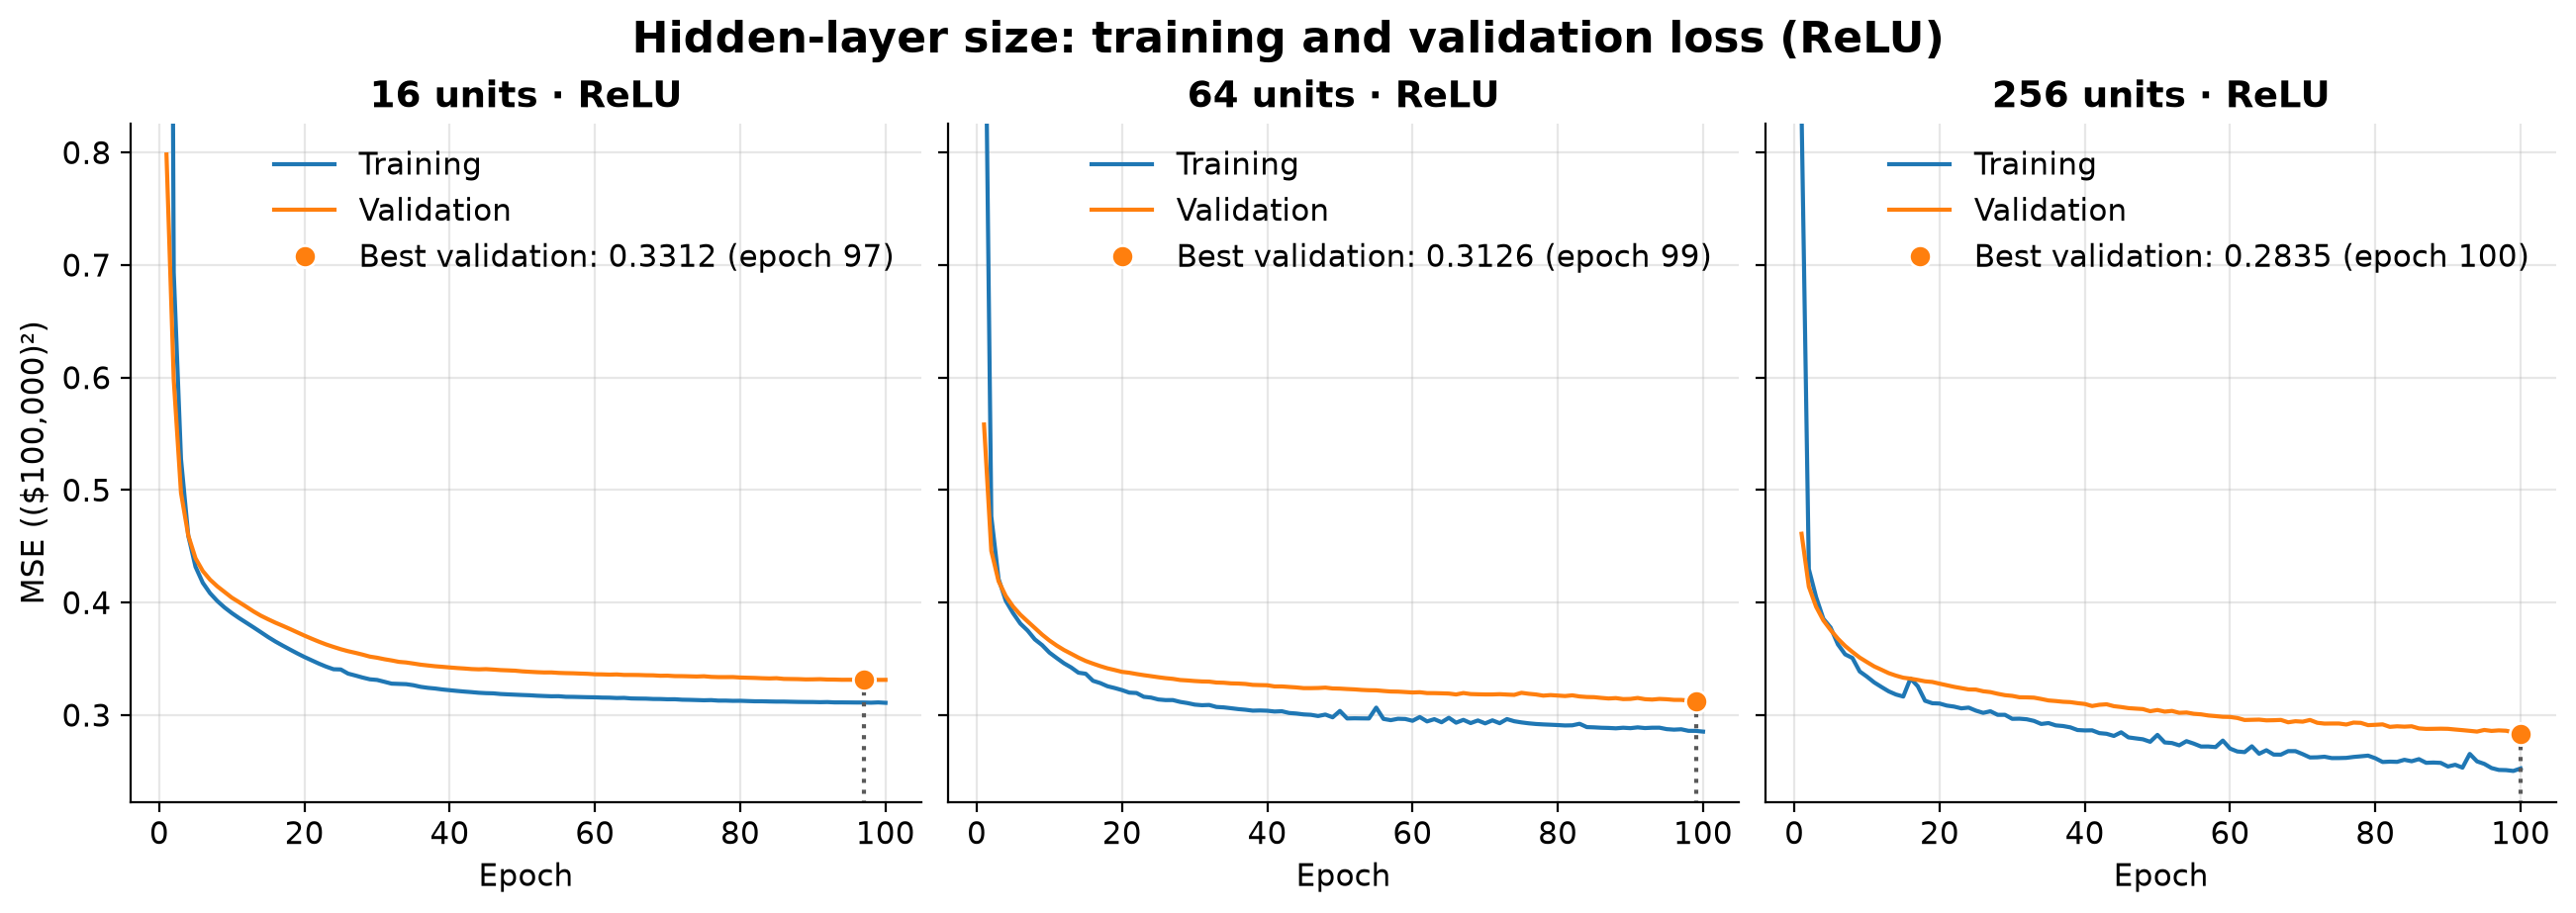

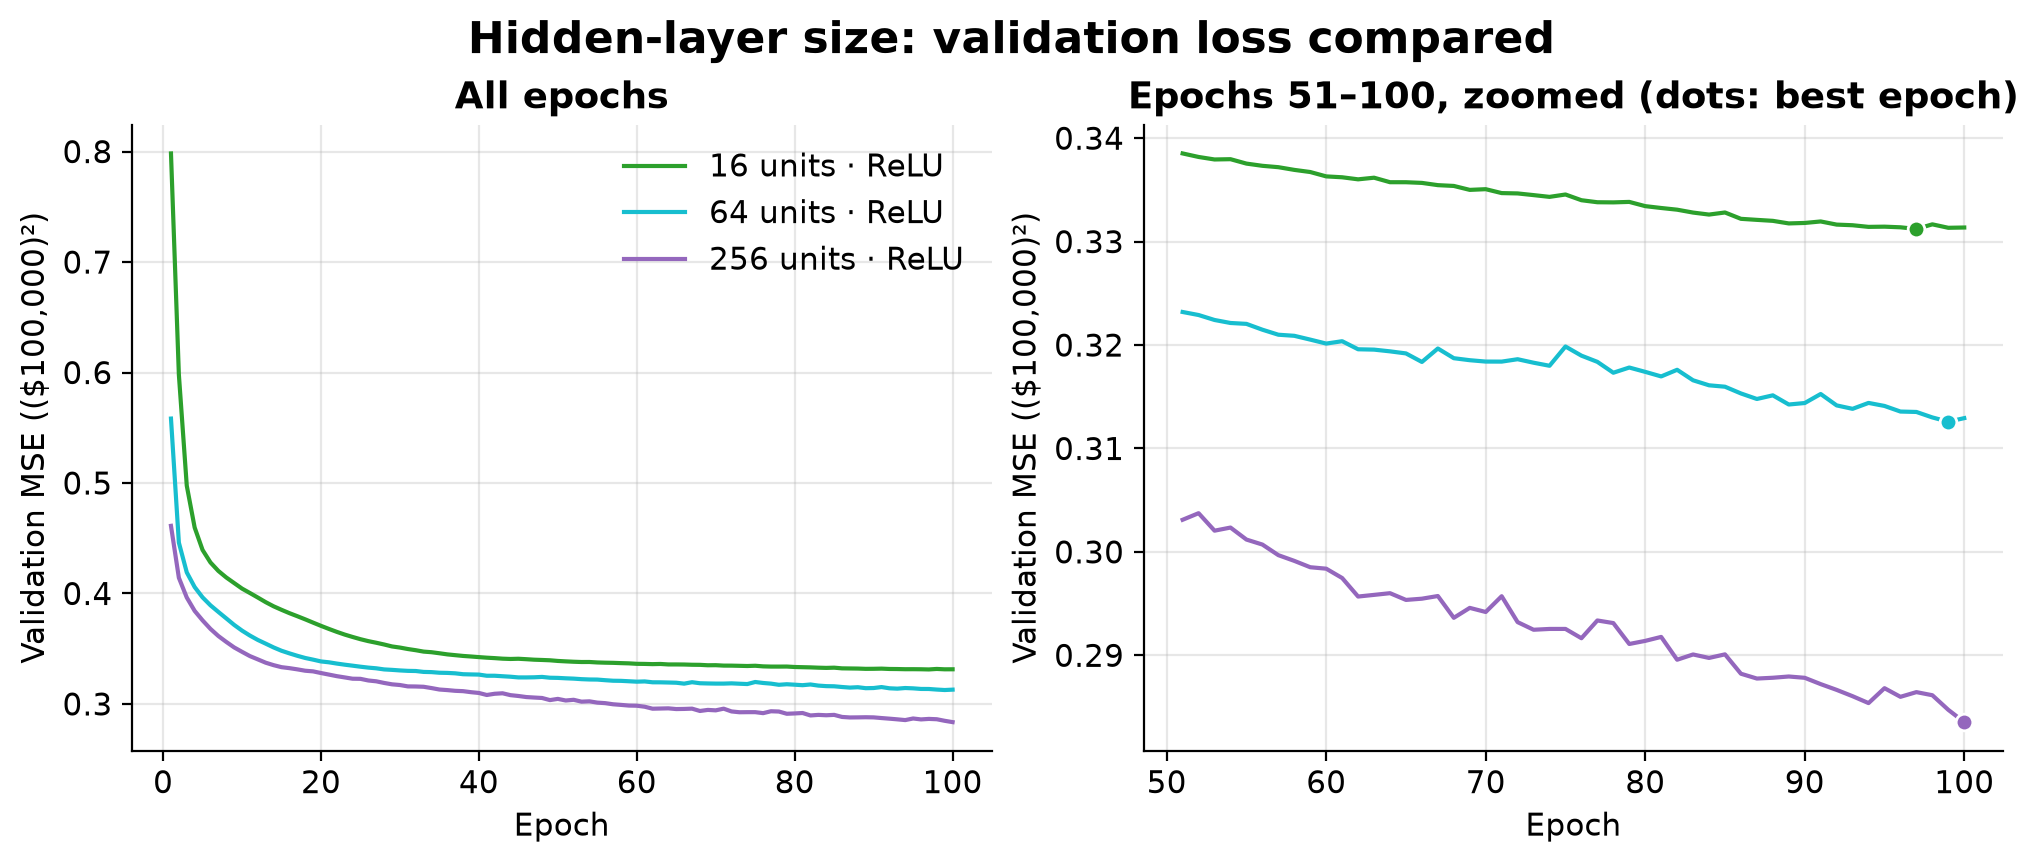

"Validation MSE (($100,000)²)",16 units · ReLU,64 units · ReLU,256 units · ReLU
Epoch,,,
1,0.7983,0.5583,0.4612
2,0.5980,0.4460,0.4142
5,0.4394,0.3965,0.3756
10,0.4044,0.3664,0.3472
25,0.3586,0.3337,0.3227
50,0.3389,0.3236,0.3046
75,0.3346,0.3199,0.2926
100,0.3314,0.3129,0.2835


In [14]:
def plot_validation(runs: Sequence[Run], title: str) -> None:
    """Validation MSE of every run on shared axes: all epochs, then the late epochs."""
    start = EPOCHS // 2 + 1
    fig, (full, late) = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
    for trained in runs:
        curve, style = trained.history["val_loss"], {"color": trained.config.color}
        full.plot(curve.index, curve, label=trained.config.label, **style)
        late.plot(curve.loc[start:].index, curve.loc[start:], **style)
        late.plot(trained.best_epoch, trained.best_val_loss, "o", mec="white", **style)
    full.set(title="All epochs")
    late.set(title=f"Epochs {start}–{EPOCHS}, zoomed (dots: best epoch)")
    for ax in (full, late):
        ax.set(xlabel="Epoch", ylabel=r"Validation MSE ((\$100,000)²)")
    full.legend(loc="upper right")
    fig.suptitle(title)
    plt.show()


def validation_checkpoints(runs: Sequence[Run]) -> pd.DataFrame:
    """Validation MSE of every run at the checkpoint epochs."""
    columns = {r.config.label: r.history["val_loss"].loc[CHECKPOINTS] for r in runs}
    return pd.DataFrame(columns).rename_axis(
        index="Epoch", columns="Validation MSE (($100,000)²)"
    )


plot_curves(size_runs, "Hidden-layer size: training and validation loss (ReLU)")
plot_validation(size_runs, "Hidden-layer size: validation loss compared")
validation_checkpoints(size_runs)

**Reading the results.**

- **Capacity and fit.** Parameters rise from 161 to 641 to 2,561, and final training loss falls with them, from 0.3109 to 0.2854 to 0.2526: each wider network fits the training rows more closely, the expected effect of greater capacity (lower bias).
- **Validation performance.** The gain carries over to validation: best validation loss falls from 0.3312 to 0.3126 to 0.2835. Over this range, added capacity lowers validation error rather than trading it for variance.
- **Convergence.** The widest network is ahead at every checkpoint: validation MSE at epoch 10 is 0.4044, 0.3664, and 0.3472 for 16, 64, and 256 units, and at epoch 50 0.3389, 0.3236, and 0.3046. Epochs to within 5% of best rise with width (33, 36, 61) not because the wider networks learn more slowly but because their best is lower and still falling: drift over the last 20 epochs is −0.0001, −0.0002, and −0.0004 per epoch. The 16-unit network is the closest to converged, the 256-unit network the furthest.
- **Underfitting: the 16-unit network.** It has nearly stopped improving (drift −0.0001) yet has the highest losses of the three, and its final training loss (0.3109) sits above the 256-unit network's best validation loss (0.2835). A model that plateaus while wider ones trained identically reach lower error on the same data is limited by capacity: it underfits, with high bias. The 64-unit baseline underfits less, and the 256-unit network least.
- **Overfitting: none at any width.** The best epochs fall at the end of the budget (97, 99, 100), final validation loss is within 0.0003 of the best (0.3314 vs 0.3312, 0.3129 vs 0.3126, 0.2835 vs 0.2835), and no validation curve turns upward. The generalization gap at epoch 100 widens with width, from about 0.02 at 16 units (0.3314 − 0.3109) to about 0.03 at 64 and 256 units (0.3129 − 0.2854 and 0.2835 − 0.2526): the wider networks fit some detail specific to the training rows, but gain more in fit than they lose in generalization. At 2,561 parameters for 14,448 training rows, the widest network is still small relative to the data.
- **Stability.** Width adds oscillation. Jitter rises from 0.0002 to 0.0005 to 0.0007, about twice the drift's magnitude (0.0001, 0.0002, 0.0004), so the excess, the oscillation, grows from 0.0001 to 0.0003 per epoch; the 64- and 256-unit validation curves wiggle visibly in the zoom, and the 256-unit training curve spikes near epoch 16. The oscillation stays far below the gaps between widths (0.3312 − 0.3126 = 0.0186 and 0.3126 − 0.2835 = 0.0291), so it does not blur the ranking within these runs.
- **Limits.** One seed per width leaves run-to-run variation unmeasured, so the ranking rests on single runs. The 256-unit network is still improving at epoch 100, so a longer budget could change the margins; 256 is the widest size tested, and whether a wider layer would help further or begin to overfit is not tested.

### Selection

`chosen_units` is the width with the lowest best validation loss, computed from the runs above.

In [15]:
def select(runs: Sequence[Run]) -> Run:
    """The run with the lowest best validation loss; prints it beside the runner-up."""
    best, runner_up = sorted(runs, key=lambda trained: trained.best_val_loss)[:2]
    lower = 1 - best.best_val_loss / runner_up.best_val_loss
    print(
        f"Selected: {best.config.label} "
        f"(best validation loss {best.best_val_loss:.4f}); "
        f"runner-up: {runner_up.config.label} ({runner_up.best_val_loss:.4f}); "
        f"the selection is {lower:.1%} lower"
    )
    return best


size_choice = select(size_runs)
chosen_units = size_choice.config.hidden_units

Selected: 256 units · ReLU (best validation loss 0.2835); runner-up: 64 units · ReLU (0.3126); the selection is 9.3% lower


**Selected: 256 hidden units.** Its best validation loss, 0.2835, is 9.3% below the 64-unit runner-up's 0.3126; the decision uses validation results only. Step 5 holds the width at 256.

## Step 5 — Activation functions

Three networks at Step 4's width that differ only in the hidden layer's activation.

| | Setting |
|---|---|
| Changes | Activation: ReLU, Tanh, Sigmoid (`ACTIVATIONS`) |
| Held constant | Hidden units at Step 4's choice (`chosen_units`, 256) and every other Step 4 setting: split and scaling, Adam, loss and metric, batch size, epochs, seed, best-validation weights kept; Keras default initialization (Glorot-uniform kernels, zero biases) for all three |

| Activation | Output | Why it is tested |
|---|---|---|
| ReLU | max(0, x) | Non-saturating and piecewise linear: slope 1 for every positive input, 0 otherwise. The Step 4 run at 256 units, reused from the run cache |
| Tanh | tanh(x), in (−1, 1) | Zero-centred but saturating: slope 1 at 0, falling toward 0 as the input moves away from 0 |
| Sigmoid | 1 / (1 + e⁻ˣ), in (0, 1) | Saturating and not zero-centred (every output positive, 0.5 at 0); slope at most 0.25 |

The table columns are those defined in Step 4; Parameters is dropped because all three networks have the same 2,561.

In [16]:
activation_runs = [run(Config(chosen_units, name)) for name in ACTIVATIONS]
assert run(size_choice.config) is size_choice  # Step 4's run, reused, not retrained
print(f"Distinct configurations trained in Steps 3–5: {run.cache_info().currsize}")
summarize(activation_runs, "Activation", lambda config: config.activation_name).drop(
    columns="Parameters"
)

Distinct configurations trained in Steps 3–5: 5


,Final training loss,Best validation loss,Epoch of best val loss,Final validation loss,Epochs to within 5% of best,Validation jitter,Validation drift
Activation,,,,,,,
ReLU,0.2526,0.2835,100,0.2835,61,0.0007,-0.0004
Tanh,0.3030,0.3226,100,0.3226,51,0.0002,-0.0002
Sigmoid,0.3171,0.3351,100,0.3351,76,0.0006,-0.0006


### Loss curves

Per-run panels, the comparison view, and validation MSE at the checkpoint epochs, as in Step 4.

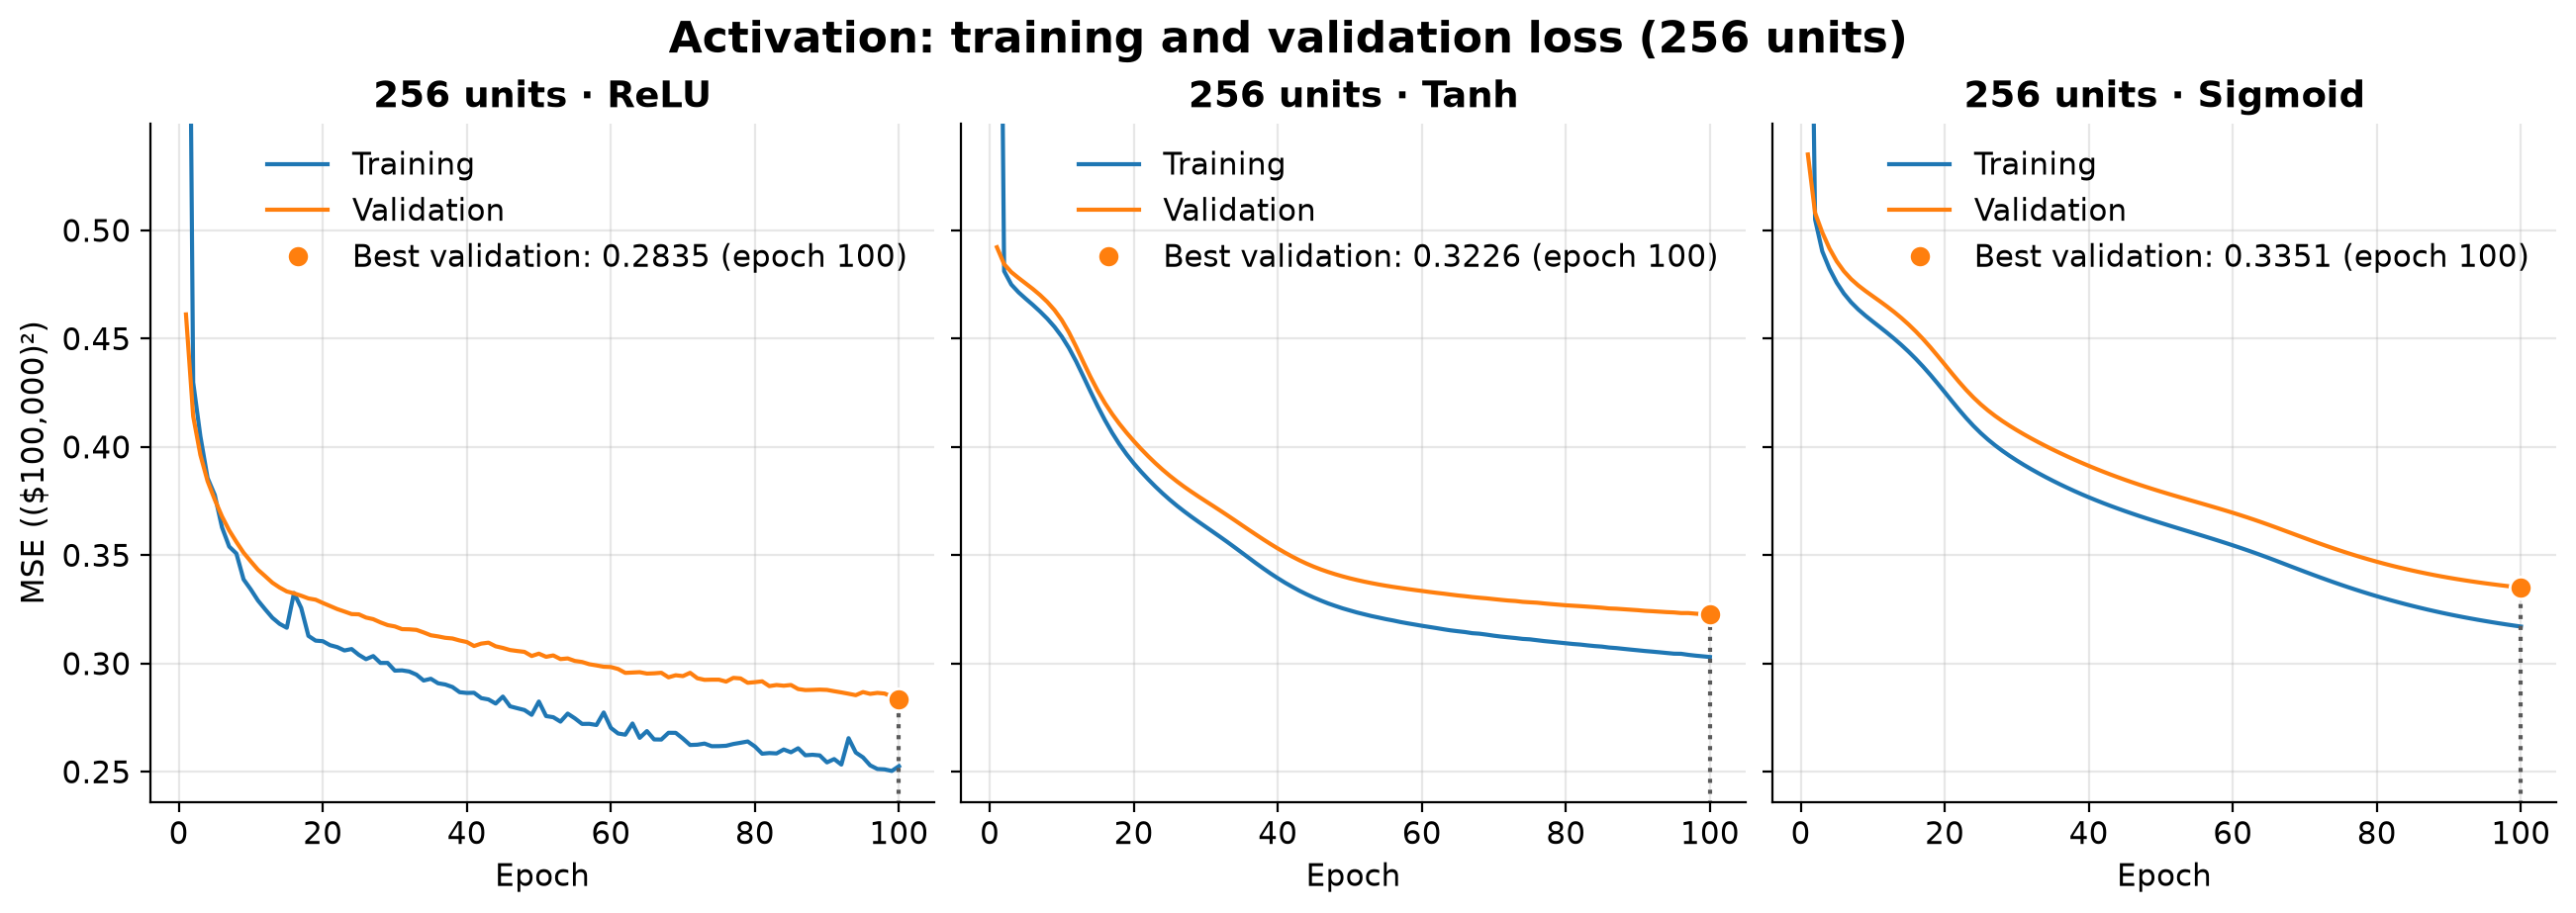

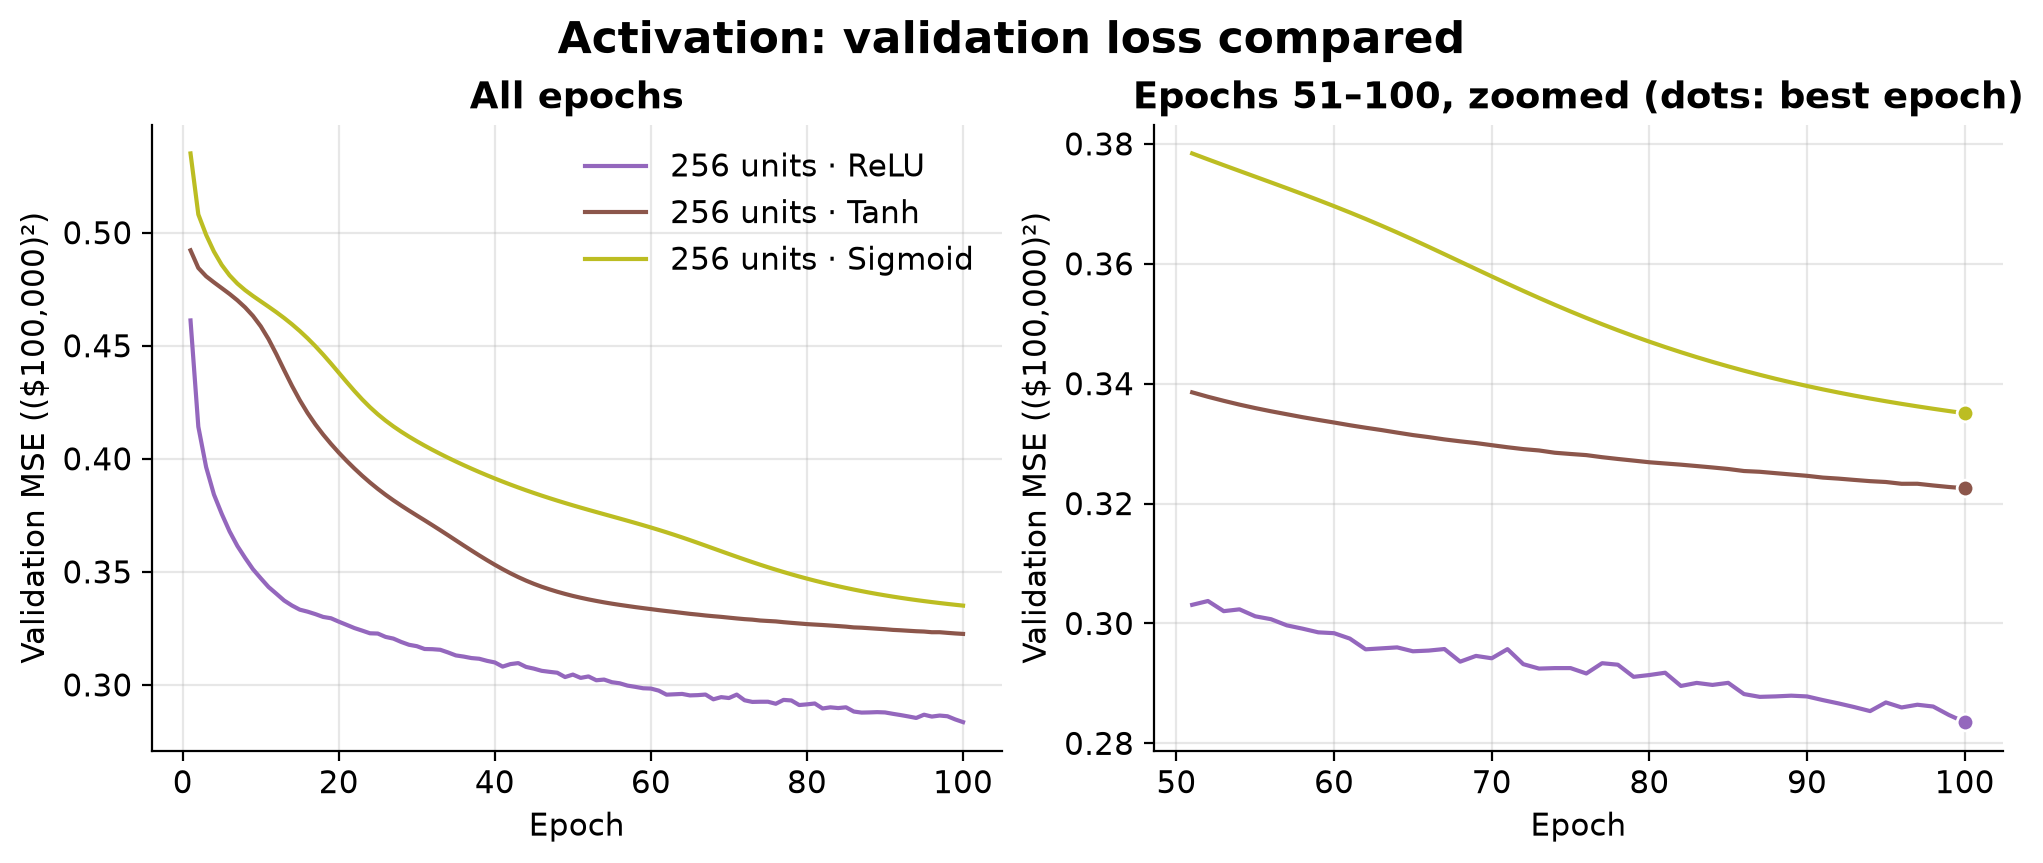

"Validation MSE (($100,000)²)",256 units · ReLU,256 units · Tanh,256 units · Sigmoid
Epoch,,,
1,0.4612,0.4922,0.5351
2,0.4142,0.4844,0.5081
5,0.3756,0.4755,0.4857
10,0.3472,0.4586,0.4696
25,0.3227,0.3867,0.4197
50,0.3046,0.3393,0.3794
75,0.2926,0.3283,0.3520
100,0.2835,0.3226,0.3351


In [17]:
plot_curves(
    activation_runs, f"Activation: training and validation loss ({chosen_units} units)"
)
plot_validation(activation_runs, "Activation: validation loss compared")
validation_checkpoints(activation_runs)

**Reading the results.**

- **Validation performance.** ReLU is best (0.2835), ahead of Tanh (0.3226) and Sigmoid (0.3351); all three reach their best at epoch 100.
- **Convergence speed.** ReLU leads from the first epoch, and the order ReLU, Tanh, Sigmoid holds at every checkpoint: at epoch 10, validation MSE is 0.3472 against 0.4586 and 0.4696. The three curves also differ in shape. ReLU drops fastest early, then decelerates: by 0.0284 over epochs 5–10 (0.3756 to 0.3472), then by only 0.0245 over the next fifteen epochs (to 0.3227 at epoch 25). Tanh stalls, then accelerates: by 0.0169 over epochs 5–10 (0.4755 to 0.4586), then by 0.0719 over epochs 10–25 (to 0.3867), the shoulder near epoch 10 in the comparison view. Sigmoid descends at a steadier pace, by 0.0161 over epochs 5–10 (0.4857 to 0.4696) and 0.0499 over epochs 10–25 (to 0.4197), and stays slowest, at 0.3794 at epoch 50. Epochs to within 5% of best rank Tanh first (51, against 61 for ReLU and 76 for Sigmoid) because Tanh's curve flattens at a higher level after epoch 50, not because it learns faster.
- **Stability.** Tanh and Sigmoid are smooth: over the last 20 epochs their jitter equals the magnitude of their drift (0.0002 and −0.0002; 0.0006 and −0.0006), a monotone decline. ReLU's jitter (0.0007) is almost twice its drift (−0.0004): its validation curve oscillates from epoch to epoch while trending down, visible in the zoom. Sigmoid's jitter is all descent: falling 0.0006 per epoch over the last 20 epochs, faster than the other two, it is the least converged of the three.
- **Fit and gap.** ReLU also fits the training rows best (final training loss 0.2526, against 0.3030 for Tanh and 0.3171 for Sigmoid) and has the widest gap at epoch 100, about 0.03 (0.2835 − 0.2526) against about 0.02 for Tanh (0.3226 − 0.3030) and Sigmoid (0.3351 − 0.3171). None overfits: final and best validation loss coincide for all three.
- **Likely mechanisms (hypotheses, not tested here).** The notebook records no pre-activations or gradients, so these explanations are consistent with the curves but unverified. ReLU is non-saturating and piecewise linear: each unit switches on or off with its input from the first step, so the network is non-linear from the start, consistent with its early lead. Tanh's stall and later acceleration fit a near-linear start: with standardized inputs and Glorot-uniform weights, pre-activations begin near 0, where tanh is nearly linear, so the network starts close to a linear model and speeds up once its weights grow into the non-linear range. Sigmoid's outputs are all positive (not zero-centred), so for each example the gradients of all 256 output weights share one sign, a known cause of zig-zagging updates (LeCun et al., 1998), consistent with its steady but slowest descent. As weights grow, saturation, units driven into the flat tails where the slope approaches 0, would slow both saturating activations further; recording pre-activations would test these hypotheses.
- **Limits.** One seed per activation leaves run-to-run variation unmeasured. All three are still falling at epoch 100, so a longer budget could change the gaps: at the current drift Sigmoid gains on ReLU (−0.0006 against −0.0004 per epoch) while Tanh falls further behind (−0.0002), but how the curves continue is not tested. All three share Keras's default Glorot-uniform initialization, as the spec requires; the comparison holds for that initialization.

### Selection

`final_run` is the activation with the lowest best validation loss at `chosen_units`, computed with the same rule as Step 4.

In [18]:
final_run = select(activation_runs)

Selected: 256 units · ReLU (best validation loss 0.2835); runner-up: 256 units · Tanh (0.3226); the selection is 12.1% lower


**Final configuration: 256 hidden units, ReLU.** Its best validation loss, 0.2835, is 12.1% below the Tanh runner-up's 0.3226; the decision uses validation results only. `final_run` is the same `Run` as Step 4's selection, and Step 6 evaluates its retained epoch-100 weights.

## Step 6 — Final model evaluation

**Final configuration: 256 hidden units, ReLU** (`final_run`), chosen in Steps 4 and 5 from validation results only.

**Approach: the best-validation-epoch weights are retained; the model is not retrained.** The evaluated model is the Step 5 run itself, holding the weights of its lowest-validation-loss epoch (restored by `RestoreBestWeights`, Step 3), so it is exactly the model validation selected, with no second training run. That epoch is 100, the last of the budget, so the retained weights are the epoch-100 weights: training ran all 100 epochs, and nothing was stopped early.

**The test set is used once, here, after every decision.** A single `predict` call scores the test split; the metrics, the table, and the diagnostics below all come from those predictions, and no result feeds back into any choice. Step 2 displayed the test split's summary statistics, which informed no decision; this is the only time a model is evaluated on it.

The check below first scores the retained model on validation again: it must reproduce the best validation loss recorded during training, confirming that the evaluated weights are the selected ones.

In [19]:
best_val_mae = float(final_run.history.loc[final_run.best_epoch, "val_mae"])
val_mse, val_mae = final_run.model.evaluate(data.val.X, data.val.y, verbose=0)
float32_tolerance = np.finfo(np.float32).resolution
assert np.isclose(val_mse, final_run.best_val_loss, rtol=float32_tolerance)
assert np.isclose(val_mae, best_val_mae, rtol=float32_tolerance)
print(f"Retained weights, scored now:     MSE {val_mse:.7f}, MAE {val_mae:.7f}")
print(
    f"Recorded at epoch {final_run.best_epoch} in training: "
    f"MSE {final_run.best_val_loss:.7f}, MAE {best_val_mae:.7f}"
)

Retained weights, scored now:     MSE 0.2835391, MAE 0.3635325
Recorded at epoch 100 in training: MSE 0.2835391, MAE 0.3635325


### Test-set evaluation

The spec's report items, plus validation MAE at the best epoch (for comparison with test MAE) and the dollar MAE.

In [20]:
# ravel: a (n, 1) column minus the (n,) target would broadcast to an (n, n) matrix.
predictions = final_run.model.predict(data.test.X, verbose=0).ravel()
test_errors = predictions - data.test.y
test_mse = float(np.mean(test_errors**2))
test_mae = float(np.mean(np.abs(test_errors)))
dollar_mae = round(test_mae, 4) * TARGET_UNIT_DOLLARS  # the 4-decimal MAE shown

report = {
    "Final configuration": final_run.config.label,
    "Best validation loss (MSE, ($100,000)²)": f"{final_run.best_val_loss:.4f}",
    "Validation MAE at the best epoch ($100,000)": f"{best_val_mae:.4f}",
    "Test MSE (($100,000)²)": f"{test_mse:.4f}",
    "Test MAE ($100,000)": f"{test_mae:.4f}",
    "Approximate dollar MAE (MAE × $100,000)": f"${dollar_mae:,.0f}",
    "Training epochs": (
        f"{EPOCHS} trained; weights of epoch {final_run.best_epoch} (best) retained"
    ),
}
pd.DataFrame.from_dict(report, orient="index", columns=["Value"]).rename_axis("Item")

,Value
Item,
Final configuration,256 units · ReLU
"Best validation loss (MSE, ($100,000)²)",0.2835
"Validation MAE at the best epoch ($100,000)",0.3635
"Test MSE (($100,000)²)",0.2668
"Test MAE ($100,000)",0.3530
"Approximate dollar MAE (MAE × $100,000)","$35,300"
Training epochs,100 trained; weights of epoch 100 (best) retained


### Regression diagnostics

Two diagnostics from the same predictions, with no further model call on the test split. The error is prediction − true value, so a negative mean signed error (bias) means under-prediction. Bands are \$100,000 wide on the true value; the band [4, 5] includes values of exactly 5.0, which lie below the cap, and the capped block groups, stored as 5.00001, form their own band. The last row covers every test row and reproduces the test MAE above.

In [21]:
def error_bands(y_true: np.ndarray, errors: np.ndarray) -> pd.DataFrame:
    """Rows, MAE, bias, and share of squared error per $100,000 band of true value."""
    top = int(TARGET_CAP) - 1  # lower edge of the last band below the cap
    labels = [f"[{low}, {low + 1})" for low in range(top)] + [f"[{top}, {top + 1}]"]
    cap_label = f"At the cap ({TARGET_CAP:g})"
    band_index = np.minimum(np.floor(y_true), top).astype(int)
    bands = np.where(y_true == TARGET_CAP, cap_label, np.array(labels)[band_index])
    groups = {label: errors[bands == label] for label in [*labels, cap_label]}
    groups["All test rows"] = errors
    table = pd.DataFrame.from_dict(
        {
            label: {
                "Rows": len(group),
                "Share of rows (%)": f"{100 * len(group) / len(errors):.2f}",
                "MAE ($100,000)": np.abs(group).mean(),
                "Mean signed error ($100,000)": group.mean(),
                "Share of squared error (%)": (
                    f"{100 * np.sum(group**2) / np.sum(errors**2):.2f}"
                ),
            }
            for label, group in groups.items()
        },
        orient="index",
    )
    return table.astype({"Rows": int}).rename_axis("True value ($100,000)")


error_bands(data.test.y, test_errors)

,Rows,Share of rows (%),"MAE ($100,000)","Mean signed error ($100,000)",Share of squared error (%)
"True value ($100,000)",,,,,
"[0, 1)",527,17.02,0.2236,0.1736,7.73
"[1, 2)",1261,40.73,0.2834,0.1424,24.71
"[2, 3)",730,23.58,0.3553,0.0170,19.24
"[3, 4)",318,10.27,0.5095,-0.2284,17.40
"[4, 5]",124,4.01,0.7439,-0.6745,13.47
At the cap (5.00001),136,4.39,0.7660,-0.7519,17.44
All test rows,3096,100.00,0.3530,0.0080,100.00


The scatter puts each test block group's prediction against its true value: points on the dashed diagonal are exact, points below it are under-predicted. Capped block groups sit on the dotted cap line; their true values could lie anywhere to its right.

Predictions above the cap: 12 of 3,096; capped block groups predicted below the cap: 126 of 136
Largest absolute error: 4.3594 (true 1.6250, predicted 5.9844); features above their training maximum: AveBedrms 34.07 (training maximum 25.64)


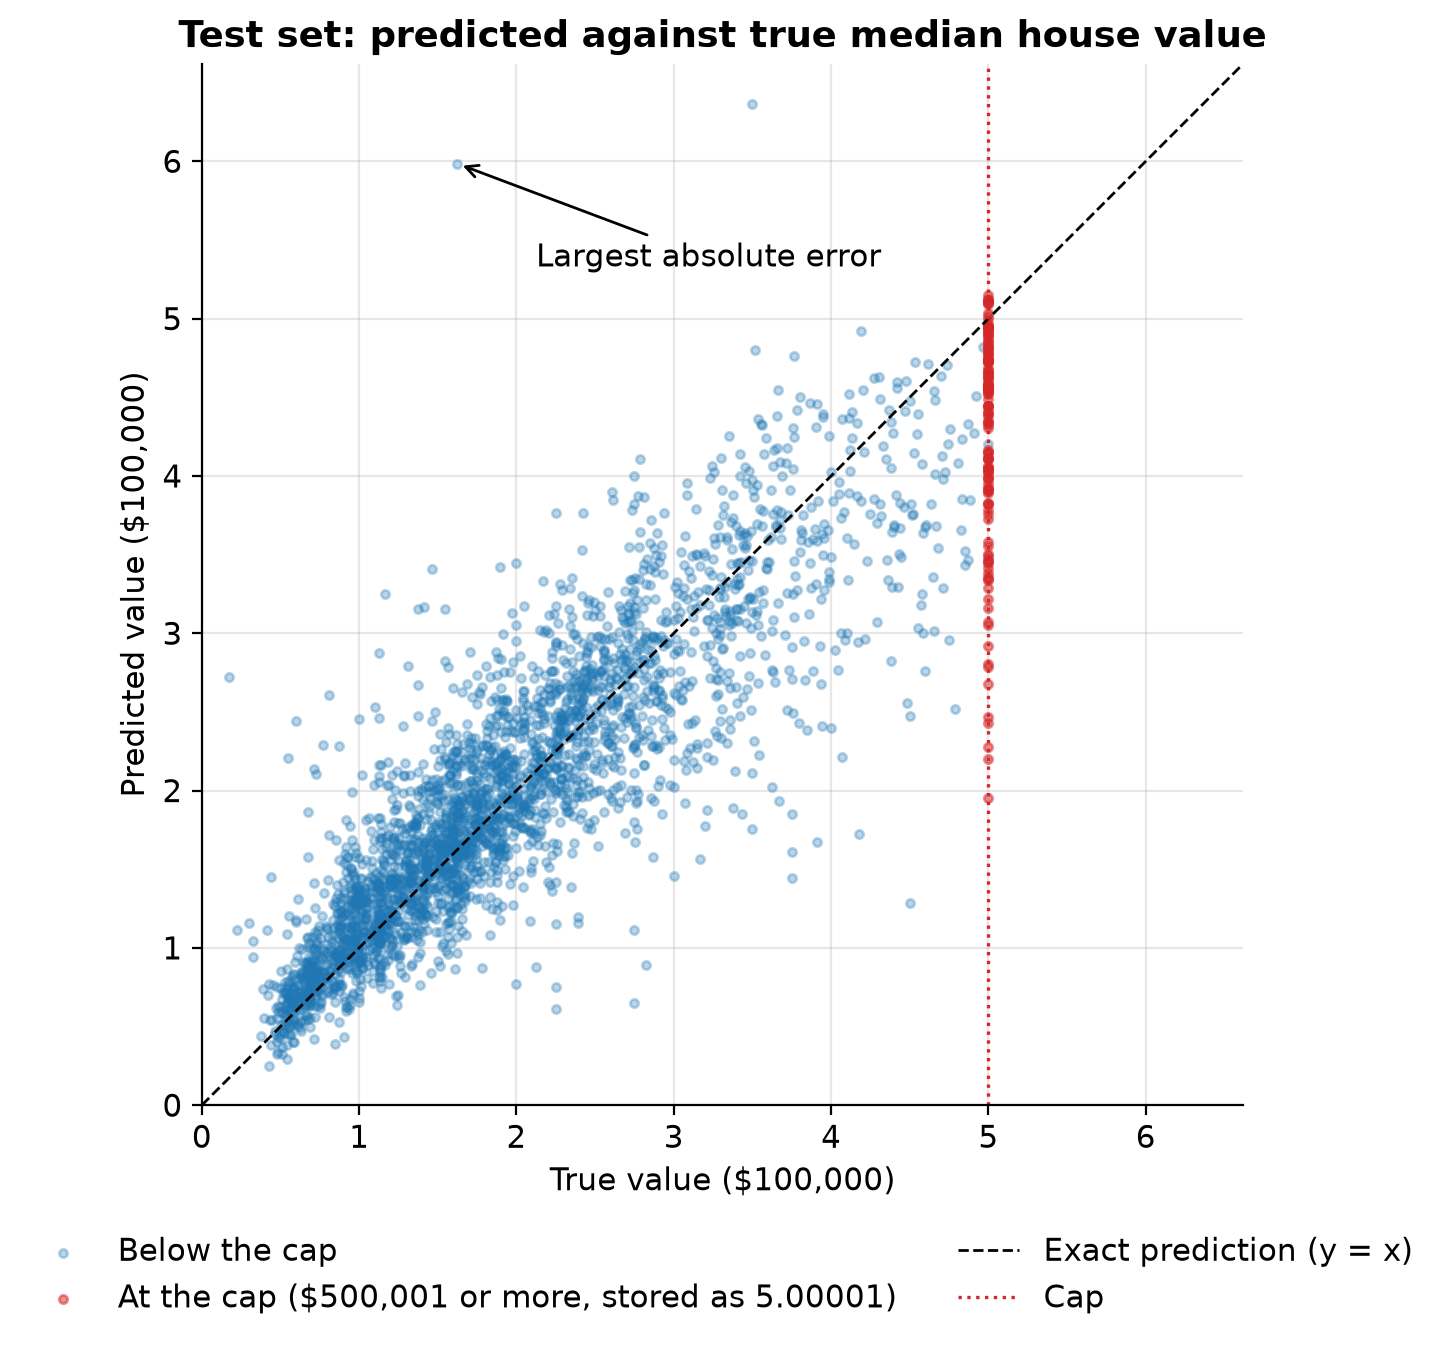

In [22]:
def plot_predictions(y_true: np.ndarray, predicted: np.ndarray, highlight: int) -> None:
    """Predicted against true value, the y = x line, the cap, and one row annotated."""
    capped = y_true == TARGET_CAP
    limit = 1.04 * max(float(predicted.max()), TARGET_CAP)
    _, ax = plt.subplots(figsize=(7, 8), layout="constrained")
    ax.scatter(
        y_true[~capped], predicted[~capped], s=9, alpha=0.3, label="Below the cap"
    )
    ax.scatter(
        y_true[capped],
        predicted[capped],
        s=9,
        alpha=0.5,
        color="C3",
        label=rf"At the cap (\$500,001 or more, stored as {TARGET_CAP:g})",
    )
    ax.plot(
        [0, limit], [0, limit], "k--", linewidth=1, label="Exact prediction (y = x)"
    )
    ax.axvline(TARGET_CAP, color="C3", linestyle=":", linewidth=1.2, label="Cap")
    ax.annotate(
        "Largest absolute error",
        xy=(y_true[highlight], predicted[highlight]),
        xytext=(y_true[highlight] + 0.5, predicted[highlight] - 0.6),
        va="center",
        arrowprops={"arrowstyle": "->"},
    )
    ax.set(
        title="Test set: predicted against true median house value",
        xlabel=r"True value (\$100,000)",
        ylabel=r"Predicted value (\$100,000)",
        xlim=(0, limit),
        ylim=(0, limit),
        aspect="equal",
    )
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=2)
    plt.show()


capped = data.test.y == TARGET_CAP
worst = int(np.argmax(np.abs(test_errors)))
worst_row = zip(X.columns, raw.test.X[worst], raw.train.X.max(axis=0), strict=True)
out_of_range = [
    f"{name} {value:.2f} (training maximum {bound:.2f})"
    for name, value, bound in worst_row
    if value > bound
]
print(
    f"Predictions above the cap: {np.sum(predictions > TARGET_CAP)} of "
    f"{len(predictions):,}; capped block groups predicted below the cap: "
    f"{np.sum(predictions[capped] < TARGET_CAP)} of {capped.sum()}"
)
print(
    f"Largest absolute error: {abs(test_errors[worst]):.4f} "
    f"(true {data.test.y[worst]:.4f}, predicted {predictions[worst]:.4f}); "
    f"features above their training maximum: {', '.join(out_of_range) or 'none'}"
)
plot_predictions(data.test.y, predictions, highlight=worst)

**Reading the evaluation.**

- **Test performance.** Scored again on validation, the retained weights reproduce the recorded best validation loss to seven decimals (0.2835391), so the model tested is the one selected. On test it scores MSE 0.2668 and MAE 0.3530, slightly below the best validation loss (0.2835) and the validation MAE at that epoch (0.3635). The test figures are the unbiased estimate for this model because no decision used them; validation chose among five configurations and 100 epochs, so if either estimate is optimistic, it is validation's. A lower test score is not evidence that the model generalizes better to test: both splits are single random samples of 3,096 rows, and the difference (0.2835 − 0.2668 = 0.0167 in MSE) is more likely sampling variation between them than a property of the model. The notebook does not measure that variation.
- **Dollar interpretation.** 0.3530 × \$100,000 ≈ \$35,300: on average, the predicted median house value of a test block group is off by about \$35,300 in 1990 dollars, roughly a sixth of the test split's mean value (0.3530 / 2.0660 ≈ 17%, Step 2). It is the error on a block group's median, not on the price of an individual house (Step 1), and it is an average over values whose errors differ widely, as the bands show.
- **Error by value: compression toward the middle.** Error grows with the true value: MAE rises from 0.2236 in [0, 1) to 0.3553 in [2, 3), 0.5095 in [3, 4), and 0.7439 in [4, 5]. The bias changes sign along the way: block groups below 2 are over-predicted (+0.1736 and +0.1424), those in [2, 3) are nearly unbiased (+0.0170), and those above 3 are under-predicted (−0.2284 in [3, 4), −0.6745 in [4, 5]). The scatter shows the same pattern: at the low end the cloud sits above the diagonal, and above about 3.5 most points fall below it. The overall bias is near zero (+0.0080) only because these errors cancel. A likely explanation, not tested here, is regression toward the mean: a model trained with MSE predicts roughly the average value of training rows with similar features, and where the eight features leave value uncertain, that average lies closer to the middle of the distribution than the true value does.
- **The cap.** Step 1 noted that capped labels are floors, not measurements, and the test errors should be read with that in mind. The 136 capped block groups make up 4.39% of the test rows but carry 17.44% of the squared error. They also have the largest MAE of any band (0.7660) and the most negative bias (−0.7519): on average they are predicted at about 4.2481 (5.00001 − 0.7519), roughly \$424,800, against a label of \$500,001 that is only a lower bound. For the 126 of 136 predicted below the cap, the true value lies at or above the label, so the true error is at least the measured one. The capped band's MAE and its share of squared error therefore understate the model's error on expensive areas, by an amount the data cannot reveal. The cap limits how well these block groups can be represented in three ways. No training target exceeds 5.00001, so the network never sees a value above the cap. Training penalizes any prediction above 5.00001 for a capped block, which pulls predictions for expensive areas down, although the linear output can exceed the cap (12 test predictions do). And one label covers every block group worth \$500,001 or more, however much more. Censoring is not the whole story: under-prediction already reaches −0.6745 in [4, 5], where labels are exact, so the compression above likely contributes too. How much each cause contributes is not tested.
- **Largest error.** The single largest error, 4.3594, is the annotated point in the scatter: a block group valued at 1.6250 and predicted at 5.9844, above the cap. Its `AveBedrms` (34.07) exceeds the training maximum (25.64), so here the network extrapolates beyond the range it was fit on. A likely explanation, not tested here: a ReLU network is piecewise linear, so beyond the training range its output keeps changing linearly with the input, and nothing bounds it.
- **Limits.** These results come from one training seed on one random split, so the test numbers are a single draw. Because neighboring block groups fall on both sides of the split (Step 1), the test numbers likely overstate accuracy on regions absent from training. No decision in this notebook was made from test results: the configuration, the retained epoch, and the approach were all fixed before the single `predict` call, and the test set was evaluated once.

## Final analysis and reflection

### Question 1

Hidden-layer size acted on capacity, and more capacity helped across the range tested. With ReLU fixed, parameters rose from 161 to 641 to 2,561, final training loss fell from 0.3109 to 0.2854 to 0.2526, and best validation loss fell with it, from 0.3312 to 0.3126 to 0.2835. The 16-unit network underfits: it had nearly stopped improving (validation drift −0.0001 per epoch) while its final training loss, 0.3109, still exceeded the 256-unit network's best validation loss. No width overfit within 100 epochs: the best epochs fell at 97, 99, and 100, final validation loss stayed within 0.0003 of the best, and no validation curve turned upward. The epoch-100 train/validation gap widened from about 0.02 at 16 units to about 0.03 at 64 and 256 units: the wider networks fit more training-specific detail, yet their validation loss kept falling. The widest network led at every checkpoint yet was the least converged (drift −0.0004) and oscillated the most (jitter 0.0007).

At 256 units, the activation changed how fast and how smoothly the network learned. ReLU led at every checkpoint (0.3472 at epoch 10, against 0.4586 for Tanh and 0.4696 for Sigmoid) and ended lowest (0.2835, against 0.3226 and 0.3351). Tanh stalled until about epoch 10 and then accelerated; Sigmoid descended steadily but slowest (consistent with ReLU's non-saturating units, Tanh's near-linear start, and Sigmoid's non-zero-centred outputs; untested). Tanh and Sigmoid declined smoothly, while ReLU oscillated around its downward trend. None overfit: all three reached their best at epoch 100. Tanh and Sigmoid also fit the training rows less closely (final training loss 0.3030 and 0.3171, against 0.2526), so at epoch 100 they underfit more than ReLU; both are still falling, Sigmoid fastest (drift −0.0006 per epoch), so part of that shortfall is likely slower convergence rather than a limit of the activation. Each selection used validation loss alone: 256 units, 9.3% below the 64-unit runner-up, then ReLU, 12.1% below Tanh, so the final model is 256 units · ReLU with its epoch-100 weights. Both margins far exceed the late-epoch oscillation, but each rests on one seed, and a longer budget could change them.

### Question 2

The final model generalizes to held-out block groups from the same distribution about as well as validation predicted. Test MSE is 0.2668 and test MAE 0.3530 (about \$35,300 in 1990 dollars), against 0.2835 and 0.3635 on validation. The lower test score is more likely sampling variation between two random samples of 3,096 rows than better generalization; the test set was evaluated once and informed no decision. The train/validation gap is small (0.2835 − 0.2526 ≈ 0.03) and validation loss never turned upward, so the remaining error is mostly bias or noise the eight features cannot explain, with little variance. Step 6 shows that error is systematic: low values are over-predicted and high values under-predicted, MAE rises from 0.2236 in [0, 1) to 0.7439 in [4, 5], and the capped band has the largest MAE (0.7660) and the most negative bias (−0.7519). Three caveats apply: one seed leaves run-to-run variation unmeasured; the random split puts spatially correlated neighbors on both sides, so the test numbers likely overstate accuracy on regions absent from training; and capped labels are lower bounds, so the error on expensive areas is understated.

One technique the evidence points to is a longer training budget with early stopping on validation loss. All five configurations reached their best validation loss in epochs 97 to 100, and the final model's validation loss was still falling at epoch 100 (drift −0.0004 per epoch): the fixed budget, not overfitting, ended training. Regularization such as dropout is not indicated: it reduces variance, and the small gap leaves little to reduce. Early stopping halts the longer run once validation stops improving. To validate it, the 256-unit ReLU network would be retrained over the same several seeds at both the 100-epoch budget and the longer one (for example 500 epochs, patience 20), keeping the longer budget only if its mean best validation loss improves by more than the seed-to-seed spread; the test set would play no part. Any gain is a hypothesis: the curves are decelerating, and their course past epoch 100 is untested. Nor would it reduce the error the cap imposes.

### References

The data are Pace and Barry's (1997) California Housing set, loaded with scikit-learn (Pedregosa et al., 2011). Models are built and trained with Keras (Chollet et al., 2015) on TensorFlow (Abadi et al., 2015), using two Keras defaults the notebook names: the Adam optimizer (Kingma & Ba, 2015) and Glorot-uniform initialization (Glorot & Bengio, 2010). Step 5's account of non-zero-centred activations follows LeCun et al. (1998). Arrays, tables, and figures use NumPy (Harris et al., 2020), pandas (McKinney, 2010), and Matplotlib (Hunter, 2007).

Abadi, M., Agarwal, A., Barham, P., Brevdo, E., Chen, Z., Citro, C., Corrado, G. S., Davis, A., Dean, J., Devin, M., Ghemawat, S., Goodfellow, I., Harp, A., Irving, G., Isard, M., Jia, Y., Jozefowicz, R., Kaiser, L., Kudlur, M., . . . Zheng, X. (2015). *TensorFlow: Large-scale machine learning on heterogeneous systems* [Computer software]. <https://www.tensorflow.org/>

Chollet, F., & others. (2015). *Keras* [Computer software]. <https://keras.io>

Glorot, X., & Bengio, Y. (2010). Understanding the difficulty of training deep feedforward neural networks. In Y. W. Teh & M. Titterington (Eds.), *Proceedings of the Thirteenth International Conference on Artificial Intelligence and Statistics* (pp. 249–256). PMLR. <https://proceedings.mlr.press/v9/glorot10a.html>

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., Fernández del Río, J., Wiebe, M., Peterson, P., . . . Oliphant, T. E. (2020). Array programming with NumPy. *Nature*, *585*(7825), 357–362. <https://doi.org/10.1038/s41586-020-2649-2>

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering*, *9*(3), 90–95. <https://doi.org/10.1109/MCSE.2007.55>

Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. In *3rd International Conference on Learning Representations (ICLR 2015)*. <https://arxiv.org/abs/1412.6980>

LeCun, Y., Bottou, L., Orr, G. B., & Müller, K.-R. (1998). Efficient BackProp. In G. B. Orr & K.-R. Müller (Eds.), *Neural networks: Tricks of the trade* (Lecture Notes in Computer Science, Vol. 1524, pp. 9–50). Springer. <https://doi.org/10.1007/3-540-49430-8_2>

McKinney, W. (2010). Data structures for statistical computing in Python. In S. van der Walt & J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 56–61). <https://doi.org/10.25080/Majora-92bf1922-00a>

Pace, R. K., & Barry, R. (1997). Sparse spatial autoregressions. *Statistics & Probability Letters*, *33*(3), 291–297. <https://doi.org/10.1016/S0167-7152(96)00140-X>

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, *12*, 2825–2830. <https://jmlr.org/papers/v12/pedregosa11a.html>